# Phần A: Chuẩn bị dữ liệu
## A1. Cài đặt thư viện ucimlrepo

In [ ]:
!pip install ucimlrepo

## A2. Tải dữ liệu vào Pandas DataFrame

In [ ]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Tải bộ dữ liệu
statlog_german_credit_data = fetch_ucirepo(id=144)

# Tách riêng tập đặc trưng (X) và nhãn gốc của UCI (y_uci: cột 'class', 1 = Good, 2 = Bad)
X = statlog_german_credit_data.data.features
y_uci = statlog_german_credit_data.data.targets
assert X.shape == (1000, 20)

# Xem 5 dòng đầu tiên của dữ liệu
print("Dữ liệu đầu vào (Features):")
display(X.head())

print("\nNhãn (Targets):")
display(y_uci.head())

Dữ liệu đầu vào (Features):


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201



Nhãn (Targets):


,class
0,1
1,2
2,1
3,1
4,2


## A3. Phân tích khám phá dữ liệu (EDA)
Phần này sử dụng dữ liệu thô, chưa qua chuẩn hóa tỷ lệ của `X` và `y_uci` từ A2, trước khi thực hiện bất kỳ bước co giãn hay mã hóa nào, nhằm đảm bảo mọi con số đều giữ nguyên giá trị trực quan ban đầu. Sau mỗi biểu đồ sẽ là một phần diễn giải ngắn gọn.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

GOOD, BAD = "#2f6f73", "#8a3b6e"
PAL = {"Good": GOOD, "Bad": BAD}

# Readable column names (UCI calls them Attribute1..Attribute20)
eda_names = {
    "Attribute1": "checking_status", "Attribute2": "duration_months", "Attribute3": "credit_history",
    "Attribute4": "purpose", "Attribute5": "credit_amount", "Attribute6": "savings",
    "Attribute7": "employment_since", "Attribute8": "installment_rate", "Attribute9": "personal_status_sex",
    "Attribute10": "other_debtors", "Attribute11": "residence_since", "Attribute12": "property",
    "Attribute13": "age", "Attribute14": "other_installment_plans", "Attribute15": "housing",
    "Attribute16": "existing_credits", "Attribute17": "job", "Attribute18": "num_dependents",
    "Attribute19": "telephone", "Attribute20": "foreign_worker",
}

# Decode the A11, A34... codes into plain labels (from the dataset's data dictionary)
eda_labels = {
    "checking_status": {"A11": "< 0 DM", "A12": "0-200 DM", "A13": ">= 200 DM", "A14": "no checking acct"},
    "credit_history": {"A30": "no credits/all paid", "A31": "all paid (this bank)", "A32": "existing paid duly",
                       "A33": "past delay", "A34": "critical/other credits"},
    "purpose": {"A40": "car (new)", "A41": "car (used)", "A42": "furniture/equip", "A43": "radio/TV",
                "A44": "domestic appl.", "A45": "repairs", "A46": "education", "A47": "vacation",
                "A48": "retraining", "A49": "business", "A410": "others"},
    "savings": {"A61": "< 100 DM", "A62": "100-500 DM", "A63": "500-1000 DM", "A64": ">= 1000 DM", "A65": "unknown/none"},
    "employment_since": {"A71": "unemployed", "A72": "< 1 yr", "A73": "1-4 yrs", "A74": "4-7 yrs", "A75": ">= 7 yrs"},
    "personal_status_sex": {"A91": "male div/sep", "A92": "female div/sep/mar", "A93": "male single",
                            "A94": "male mar/wid", "A95": "female single"},
    "other_debtors": {"A101": "none", "A102": "co-applicant", "A103": "guarantor"},
    "property": {"A121": "real estate", "A122": "savings/insurance", "A123": "car/other", "A124": "unknown/none"},
    "other_installment_plans": {"A141": "bank", "A142": "stores", "A143": "none"},
    "housing": {"A151": "rent", "A152": "own", "A153": "free"},
    "job": {"A171": "unemployed/unskilled non-res", "A172": "unskilled resident", "A173": "skilled",
            "A174": "management/highly qualified"},
    "telephone": {"A191": "none", "A192": "yes"},
    "foreign_worker": {"A201": "yes", "A202": "no"},
}

# Work on a separate copy so X and y_uci stay untouched for the preprocessing steps
df_eda = X.rename(columns=eda_names).copy()
for col, m in eda_labels.items():
    df_eda[col] = df_eda[col].map(m)

df_eda["bad"] = (y_uci.iloc[:, 0] == 2).astype(int)          # 1 = Bad, 0 = Good
df_eda["risk"] = df_eda["bad"].map({0: "Good", 1: "Bad"})

eda_num_cols = ["duration_months", "credit_amount", "age", "installment_rate",
                "residence_since", "existing_credits", "num_dependents"]
eda_cat_cols = list(eda_labels.keys())
df_eda.head()

,checking_status,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,age,other_installment_plans,housing,existing_credits,job,num_dependents,telephone,foreign_worker,bad,risk
0,< 0 DM,6,critical/other credits,radio/TV,1169,unknown/none,>= 7 yrs,4,male single,none,...,67,none,own,2,skilled,1,yes,yes,0,Good
1,0-200 DM,48,existing paid duly,radio/TV,5951,< 100 DM,1-4 yrs,2,female div/sep/mar,none,...,22,none,own,1,skilled,1,none,yes,1,Bad
2,no checking acct,12,critical/other credits,education,2096,< 100 DM,4-7 yrs,2,male single,none,...,49,none,own,1,unskilled resident,2,none,yes,0,Good
3,< 0 DM,42,existing paid duly,furniture/equip,7882,< 100 DM,4-7 yrs,2,male single,guarantor,...,45,none,free,1,skilled,2,none,yes,0,Good
4,< 0 DM,24,past delay,car (new),4870,< 100 DM,1-4 yrs,3,male single,none,...,53,none,free,2,skilled,2,none,yes,1,Bad


### 1. Tổng quan và chất lượng dữ liệu


In [ ]:
print("Shape:", df_eda.shape)
print("Missing values:", df_eda.isnull().sum().sum())
print("Duplicate rows:", df_eda.duplicated().sum())
print()
df_eda.info()

Shape: (1000, 22)
Missing values: 0
Duplicate rows: 0

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 22 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   checking_status          1000 non-null   object
 1   duration_months          1000 non-null   int64 
 2   credit_history           1000 non-null   object
 3   purpose                  1000 non-null   object
 4   credit_amount            1000 non-null   int64 
 5   savings                  1000 non-null   object
 6   employment_since         1000 non-null   object
 7   installment_rate         1000 non-null   int64 
 8   personal_status_sex      1000 non-null   object
 9   other_debtors            1000 non-null   object
 10  residence_since          1000 non-null   int64 
 11  property                 1000 non-null   object
 12  age                      1000 non-null   int64 
 13  other_installment_plans  1000 non-null 

In [ ]:
# Summary statistics + skewness for the numeric features
summary = df_eda[eda_num_cols].describe().T
summary["skew"] = df_eda[eda_num_cols].skew()
summary.round(2)

,count,mean,std,min,25%,50%,75%,max,skew
duration_months,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0,1.09
credit_amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0,1.95
age,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0,1.02
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0,-0.53
residence_since,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0,-0.27
existing_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0,1.27
num_dependents,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0,1.91


### 2. Biến mục tiêu

risk
Good    700
Bad     300
Name: count, dtype: int64 

risk
Good    70.0 %
Bad     30.0 %
Name: count, dtype: object


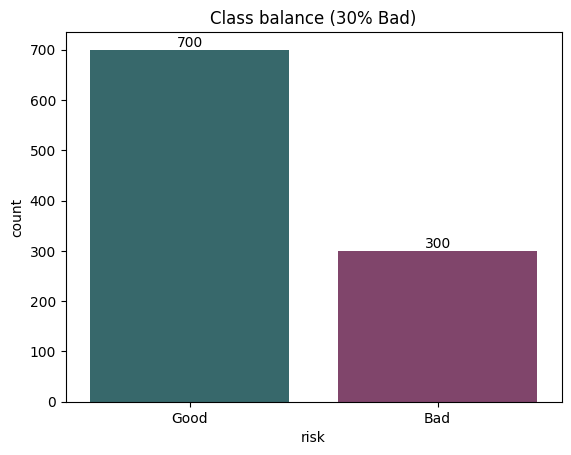

In [ ]:
counts = df_eda["risk"].value_counts()
print(counts, "\n")
print((counts / len(df_eda) * 100).round(1).astype(str) + " %")

ax = sns.countplot(data=df_eda, x="risk", order=["Good", "Bad"], palette=PAL, hue="risk", legend=False)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
ax.set_title("Class balance (30% Bad)")
plt.show()

Bộ dữ liệu bao gồm 700 hồ sơ Tốt (Good) và 300 hồ sơ Xấu (Bad), tương ứng với tỷ lệ phân bổ 70/30. Mức độ mất cân bằng này ở mức vừa phải, cho phép mô hình học được cả hai lớp mà không nhất thiết phải áp dụng các kỹ thuật tái lấy mẫu (resampling) quá mức. Điều quan trọng hơn cần lưu ý là tổn thất giữa hai loại sai số không tương đương nhau: ma trận chi phí từ tập dữ liệu UCI áp mức phạt cho việc phê duyệt nhầm một khách hàng Xấu cao gấp 5 lần so với việc từ chối nhầm một khách hàng Tốt. Do đó, chỉ dựa vào độ chính xác (accuracy) tổng thể sẽ dẫn đến đánh giá sai lệch, và các bước xây dựng mô hình tiếp theo cần áp dụng phương pháp học nhạy cảm với chi phí (cost-sensitive learning) cũng như tinh chỉnh ngưỡng phân loại (threshold tuning).

### 3. Các đặc trưng (feature) dạng số


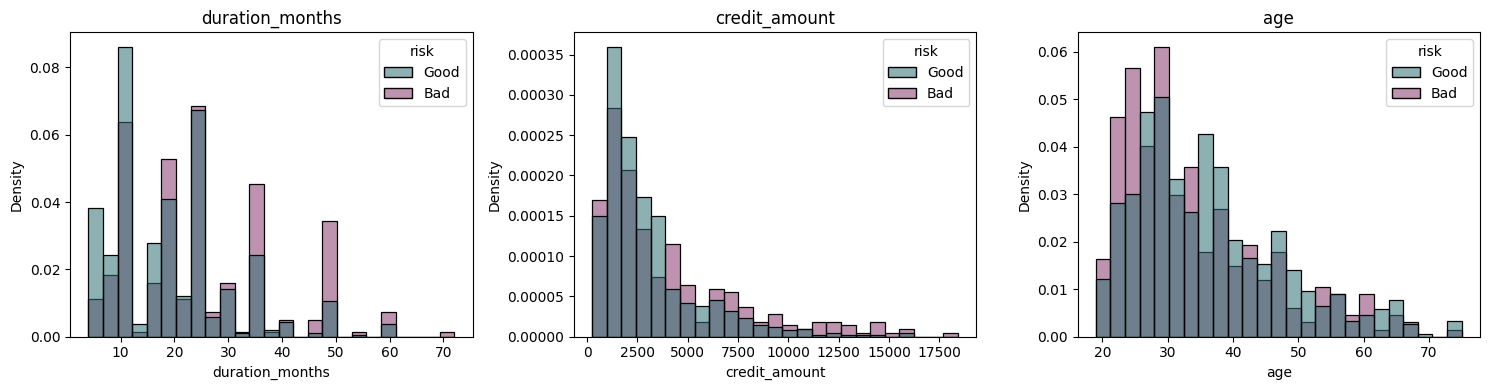

In [ ]:
# Distributions, split by Good / Bad
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["duration_months", "credit_amount", "age"]):
    sns.histplot(data=df_eda, x=col, hue="risk", palette=PAL, stat="density", common_norm=False,
                 bins=25, alpha=0.55, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

 Cả ba biến số đều có phân phối lệch phải. Thời hạn khoản vay tập trung chủ yếu ở các kỳ hạn chuẩn (12 và 24 tháng) với phần đuôi kéo dài tới 72 tháng; trong đó, các hồ sơ Xấu có xu hướng lệch nhiều hơn về phía bên phải: 34% các khoản vay Xấu có thời hạn trên 24 tháng, so với tỷ lệ 18% ở các khoản vay Tốt. Giá trị khoản vay có phần đuôi dài đại diện cho các khoản vay rất lớn, và tỷ lệ này chiếm nhiều hơn ở nhóm khách hàng Xấu. Nhóm khách hàng Xấu cũng có độ tuổi trung bình trẻ hơn, với 49% từ 30 tuổi trở xuống so với 38% ở nhóm khách hàng Tốt.

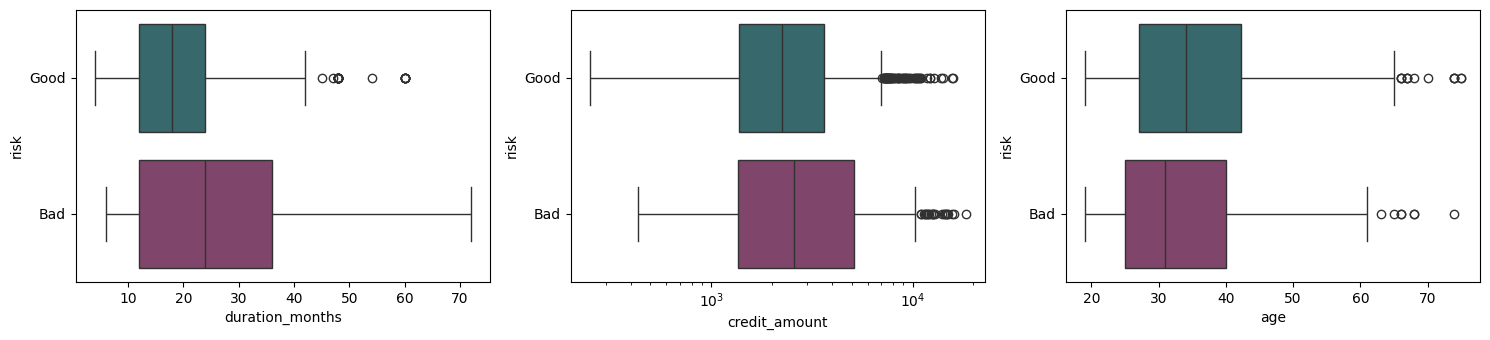

credit_amount outliers above 7,882: 72
Share of those outliers that are Bad: 54%


In [ ]:
# Boxplots (credit_amount on a log scale because it is heavily right-skewed)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, col in zip(axes, ["duration_months", "credit_amount", "age"]):
    sns.boxplot(data=df_eda, y="risk", x=col, order=["Good", "Bad"], palette=PAL, hue="risk",
                legend=False, ax=ax)
    if col == "credit_amount":
        ax.set_xscale("log")
plt.tight_layout()
plt.show()

# Outliers in credit_amount (1.5 x IQR rule)
q1, q3 = df_eda["credit_amount"].quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
n_out = (df_eda["credit_amount"] > fence).sum()
print(f"credit_amount outliers above {fence:,.0f}: {n_out}")
print(f"Share of those outliers that are Bad: {df_eda.loc[df_eda['credit_amount'] > fence, 'bad'].mean():.0%}")

In [ ]:
# Do Good and Bad differ on each numeric feature? (Mann-Whitney U: no normality assumption)
rows = []
for col in eda_num_cols:
    good, bad = df_eda.loc[df_eda.bad == 0, col], df_eda.loc[df_eda.bad == 1, col]
    _, p = stats.mannwhitneyu(good, bad)
    rows.append({"feature": col, "median_good": good.median(), "median_bad": bad.median(), "p_value": p})
pd.DataFrame(rows).round(4)

,feature,median_good,median_bad,p_value
0,duration_months,18.0,24.0,0.0000
1,credit_amount,2244.0,2574.5,0.0059
2,age,34.0,31.0,0.0004
3,installment_rate,3.0,4.0,0.0199
4,residence_since,3.0,3.0,0.9358
5,existing_credits,1.0,1.0,0.1348
6,num_dependents,1.0,1.0,0.9242


**Diễn giải (Biểu đồ hộp và kiểm định Mann-Whitney).** Nhóm hồ sơ Xấu có giá trị trung vị cao hơn về thời hạn vay (24 tháng so với 18 tháng), giá trị khoản vay trung vị cao hơn (khoảng 2.575 DM so với 2.244 DM), và độ tuổi trung vị thấp hơn (31 tuổi so với 34 tuổi). Các phép kiểm định xác nhận những chênh lệch này có ý nghĩa thống kê (thời hạn: p < 0.001; độ tuổi: p < 0.001; số tiền: p = 0.006). Thời gian cư trú, số lượng khoản tín dụng hiện có và số người phụ thuộc không cho thấy sự khác biệt đáng kể. Có 72 điểm dữ liệu ngoại lai giá trị cao, trong đó 54% thuộc nhóm Xấu, cho thấy các điểm này mang thông tin thực tế quan trọng và cần được giữ lại trong quá trình phân tích.

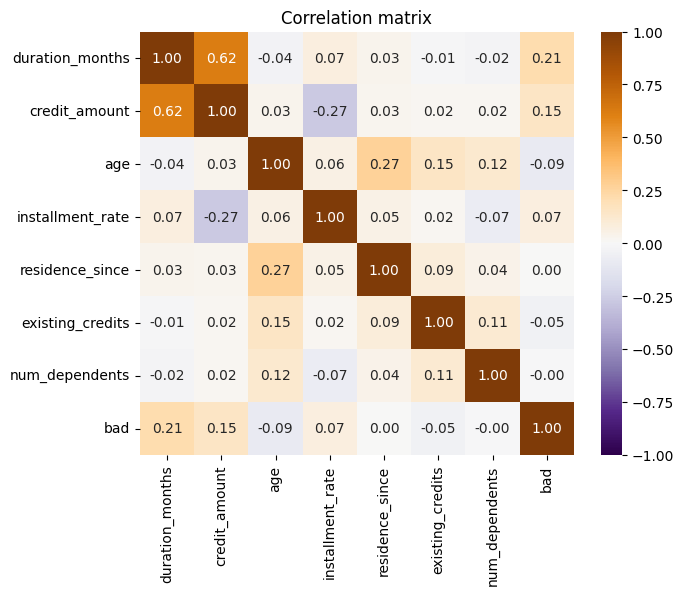

In [ ]:
# Correlation matrix (includes the target as 'bad')
plt.figure(figsize=(7, 5.5))
sns.heatmap(df_eda[eda_num_cols + ["bad"]].corr(), annot=True, fmt=".2f", cmap="PuOr_r", center=0, vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.show()

 Thời hạn vay và giá trị khoản vay là cặp biến duy nhất có mối tương quan mạnh (r = 0.62), do các khoản vay dài hạn thường đi kèm số tiền lớn hơn. Tỷ lệ trả góp có tương quan nghịch với giá trị khoản vay (r = -0.27), phản ánh việc các khoản vay lớn thường được chia nhỏ kỳ hạn để đảm bảo khả năng chi trả. Đối với biến mục tiêu, thời hạn vay (0.21) và giá trị khoản vay (0.15) có mối liên hệ thuận chiều rõ rệt nhất, độ tuổi có tương quan nghịch nhẹ (-0.09), trong khi thời gian cư trú và số người phụ thuộc gần như không có liên hệ (xấp xỉ 0). Không có biến số đơn lẻ nào đủ khả năng dự báo nguy cơ vỡ nợ một cách độc lập.

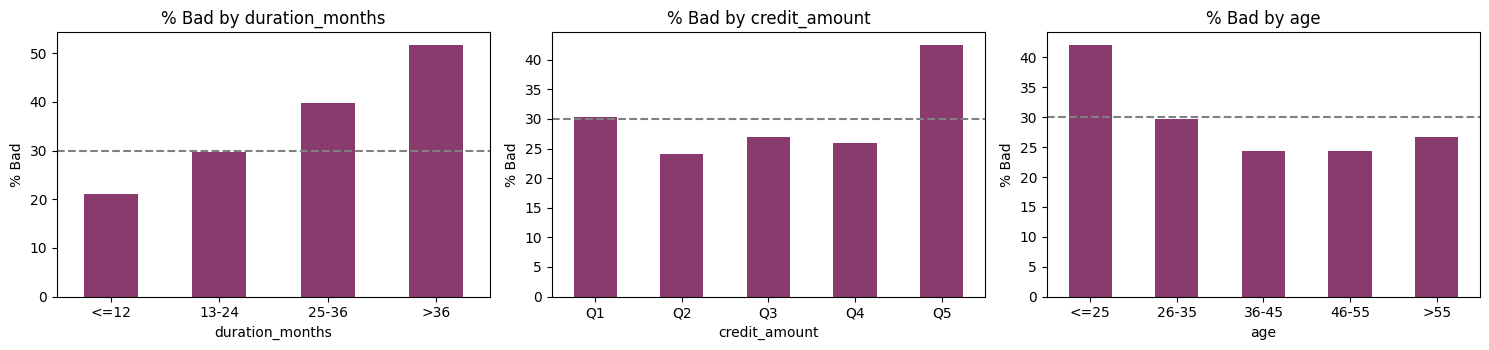

In [ ]:
# Bad rate by band: shows non-linear effects a correlation coefficient hides
bands = {
    "duration_months": pd.cut(df_eda.duration_months, [0, 12, 24, 36, 100], labels=["<=12", "13-24", "25-36", ">36"]),
    "credit_amount": pd.qcut(df_eda.credit_amount, 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]),
    "age": pd.cut(df_eda.age, [0, 25, 35, 45, 55, 100], labels=["<=25", "26-35", "36-45", "46-55", ">55"]),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (col, band) in zip(axes, bands.items()):
    rate = df_eda.groupby(band, observed=True)["bad"].mean() * 100
    rate.plot.bar(ax=ax, color=BAD, rot=0)
    ax.axhline(df_eda.bad.mean() * 100, color="gray", ls="--")
    ax.set_title(f"% Bad by {col}")
    ax.set_ylabel("% Bad")
plt.tight_layout()
plt.show()

Việc phân nhóm giúp làm rõ các xu hướng phi tuyến tính mà hệ số tương quan tuyến tính có thể bỏ sót (đường đứt đoạn biểu thị mức trung bình 30%). Tỷ lệ nợ xấu tăng đều theo thời hạn vay, từ 21% đối với các khoản vay dưới 12 tháng lên đến 52% đối với các khoản vay trên 36 tháng. Giá trị khoản vay không biến thiên tuyến tính: nhóm ngũ phân vị cao nhất (từ khoảng 4.700 DM trở lên) có tỷ lệ nợ xấu là 43%, trong khi các nhóm ở giữa dao động ở mức 24-27%. Độ tuổi thể hiện rõ xu hướng ở nhóm khách hàng trẻ: 42% nợ xấu ở nhóm từ 25 tuổi trở xuống, giảm xuống khoảng 24% ở độ tuổi từ 36 đến 55.

### 4. Các đặc trưng dạng phân loại

,feature,cramers_v,p_value
0,checking_status,0.3517,0.0000
1,credit_history,0.2484,0.0000
3,savings,0.1900,0.0000
2,purpose,0.1826,0.0001
7,property,0.1540,0.0000
4,employment_since,0.1355,0.0010
9,housing,0.1349,0.0001
8,other_installment_plans,0.1133,0.0016
5,personal_status_sex,0.0980,0.0222
6,other_debtors,0.0815,0.0361


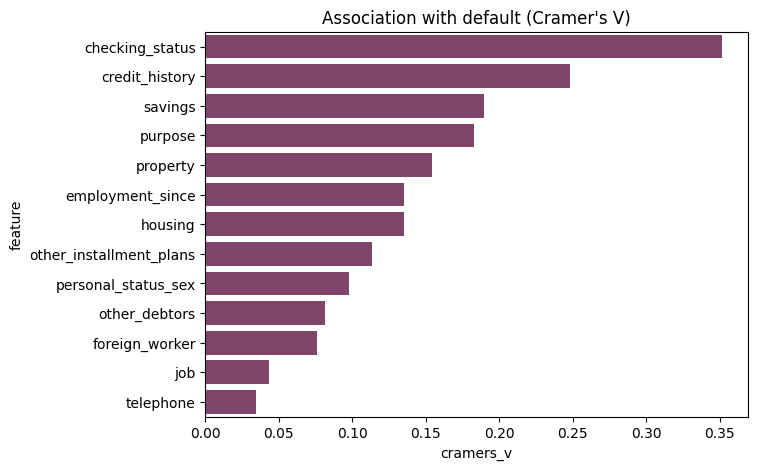

In [ ]:
# Cramer's V: strength of association between each categorical feature and the target (0 to 1)
rows = []
for col in eda_cat_cols:
    ct = pd.crosstab(df_eda[col], df_eda["bad"])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    v = np.sqrt(chi2 / (len(df_eda) * (min(ct.shape) - 1)))
    rows.append({"feature": col, "cramers_v": v, "p_value": p})
assoc = pd.DataFrame(rows).sort_values("cramers_v", ascending=False)
display(assoc.round(4))

plt.figure(figsize=(7, 5))
sns.barplot(data=assoc, y="feature", x="cramers_v", color=BAD)
plt.title("Association with default (Cramer's V)")
plt.show()

Tình trạng tài khoản thanh toán là biến phân loại có lực dự báo mạnh nhất (V = 0.35), tiếp theo là lịch sử tín dụng (0.25), tình trạng tiết kiệm (0.19) và mục đích vay (0.18). Tài sản, thời gian công tác, tình trạng nhà ở và các kế hoạch trả góp khác có mức độ ảnh hưởng nhỏ hơn nhưng vẫn có ý nghĩa thống kê (dao động trong khoảng 0.11-0.15). Loại hình công việc và việc đăng ký điện thoại không có ý nghĩa thống kê đáng kể (p = 0.60 và 0.28), cho thấy giá trị đóng góp thấp vào mô hình. Hệ số Cramér's V chỉ phản ánh mức độ liên kết giữa các biến chứ không chỉ ra chiều hướng tác động cụ thể.

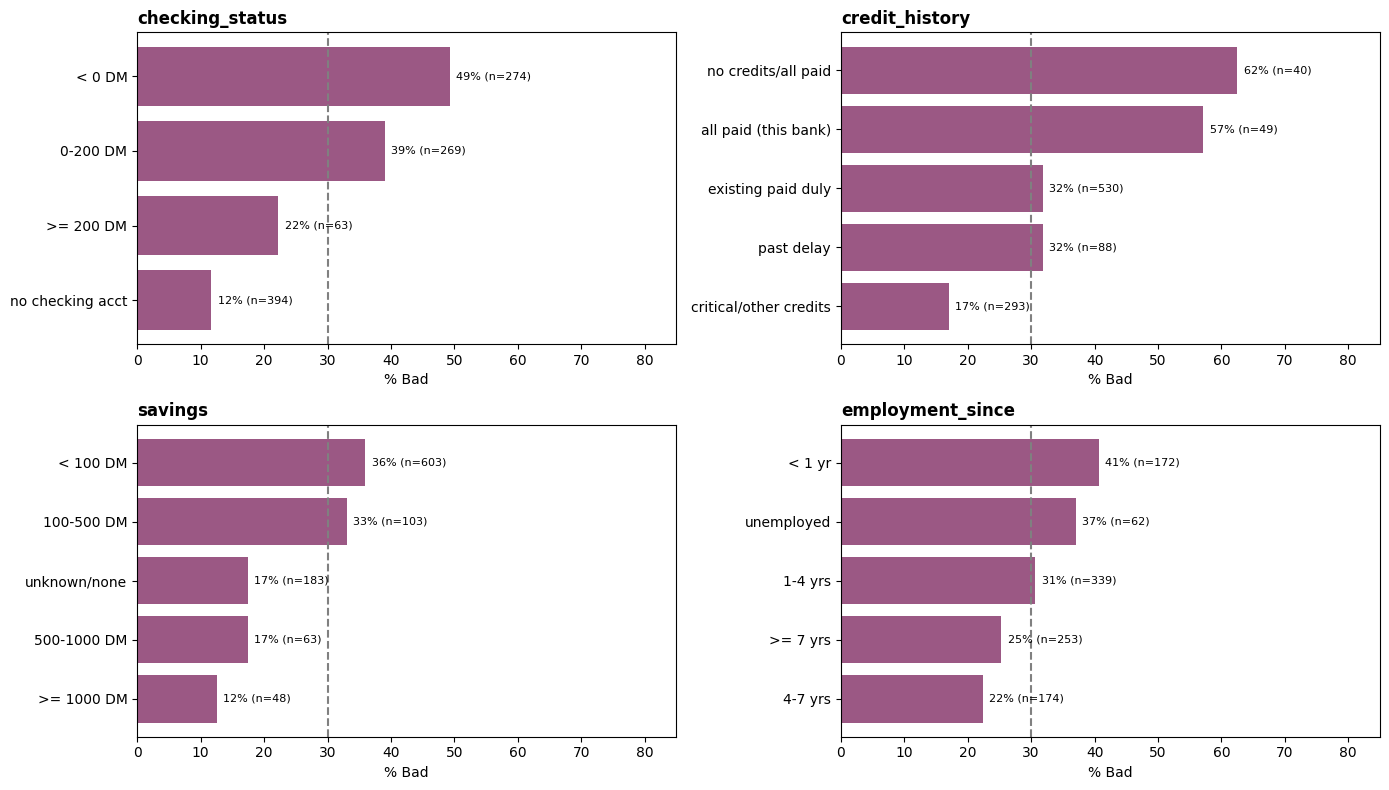

In [ ]:
# Helper: bad rate inside every category (dashed line = overall 30%). n = group size.
def plot_bad_rate(cols, nrows, ncols, figsize):
    fig, axes = plt.subplots(nrows, ncols, figsize=figsize)
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, cols):
        t = df_eda.groupby(col)["bad"].agg(["mean", "count"]).sort_values("mean")
        ax.barh(t.index, t["mean"] * 100, color=BAD, alpha=0.85)
        ax.axvline(df_eda.bad.mean() * 100, color="gray", ls="--")
        for i, (m, n) in enumerate(zip(t["mean"], t["count"])):
            ax.text(m * 100 + 1, i, f"{m*100:.0f}% (n={n})", va="center", fontsize=8)
        ax.set_xlim(0, 85)
        ax.set_xlabel("% Bad")
        ax.set_title(col, loc="left", fontweight="bold")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

# 4a. Financial standing and history
plot_bad_rate(["checking_status", "credit_history", "savings", "employment_since"], 2, 2, (14, 8))

Nhóm biến này phân tách mức độ rủi ro rõ rệt nhất. Khách hàng có số dư tài khoản vãng lai âm có tỷ lệ vỡ nợ lên tới 49%, so với 12% ở nhóm không có tài khoản vãng lai. Tiết kiệm dưới 100 DM có tỷ lệ Xấu là 36%, trong khi từ 500 DM trở lên chỉ còn 12–17%. Thời gian công tác dưới 1 năm ghi nhận tỷ lệ Xấu 41%. Lịch sử tín dụng xuất hiện xu hướng ngược với trực giác: nhóm "tài khoản rủi ro / có khoản tín dụng khác" lại là nhóm an toàn nhất (17%), trong khi nhóm "không có tín dụng / đã trả hết" lại rủi ro nhất (62%, dù cỡ mẫu chỉ 40 người); do đó nên coi đây là một điểm dị biệt (quirk) của dữ liệu.

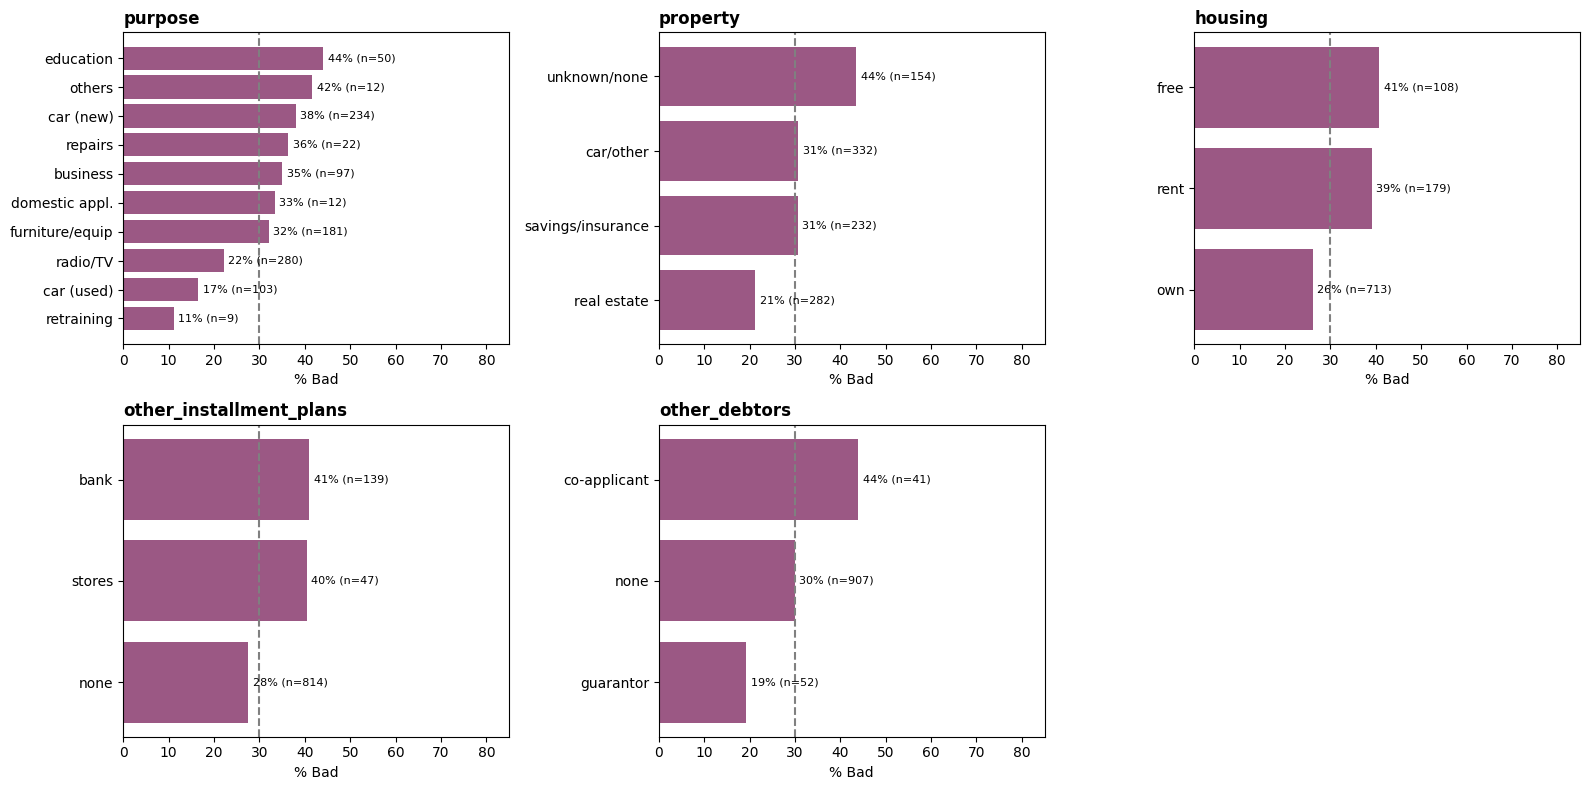

In [ ]:
# 4b. Loan purpose and assets
plot_bad_rate(["purpose", "property", "housing", "other_installment_plans", "other_debtors"], 2, 3, (16, 8))

Trong số các mục đích vay có cỡ mẫu đủ lớn, vay cho giáo dục (44%, n=50) và mua ô tô mới (38%) là rủi ro nhất; ngược lại, mua ô tô cũ (17%) và thiết bị nghe nhìn/TV (22%) là an toàn nhất. Các mục đích như đào tạo lại nghề, đồ gia dụng và "khác" đều có từ 12 khách hàng trở xuống, do đó tỷ lệ không đáng tin cậy. Nhóm sở hữu bất động sản có tỷ lệ Xấu là 21%, so với 44% ở nhóm không có tài sản xác định. Khách hàng thuê nhà hoặc ở trọ miễn phí có tỷ lệ Xấu xấp xỉ 40%, cao hơn mức 26% của nhóm sở hữu nhà. Việc có người bảo lãnh giúp giảm rủi ro (19%), trong khi có người đồng vay làm tăng rủi ro (44%, n=41).

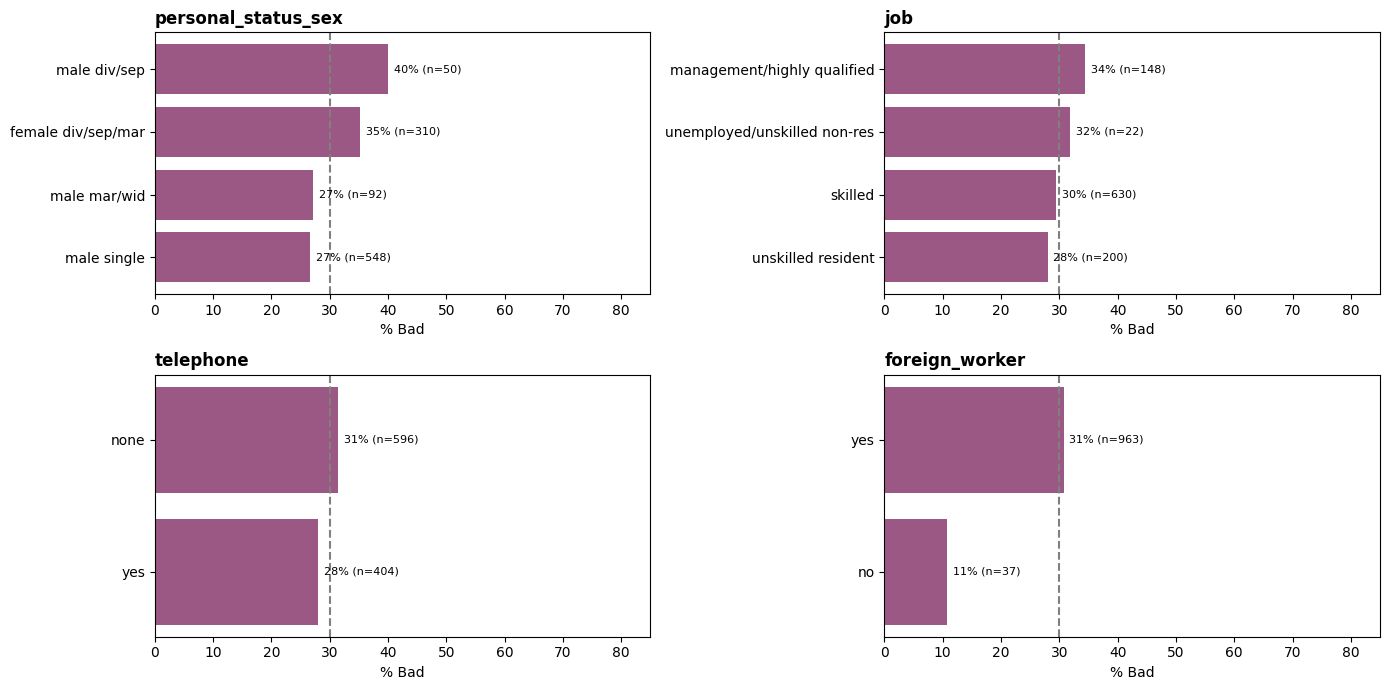

In [ ]:
# 4c. Personal attributes
plot_bad_rate(["personal_status_sex", "job", "telephone", "foreign_worker"], 2, 2, (14, 7))

Các đặc trưng này có khả năng phân tách rủi ro thấp hơn đáng kể. Nam giới độc thân có tỷ lệ Xấu 27%, nam giới ly hôn hoặc ly thân là 40% (chỉ 50 người) và nữ giới là 35%; tuy nhiên mức chênh lệch không quá lớn. Loại hình công việc (28–35%) và việc có đăng ký điện thoại (28% so với 31%) gần như không có sự khác biệt, tương ứng với kết quả kiểm định không có ý nghĩa thống kê. Nhóm 37 khách hàng không phải là lao động nước ngoài chỉ có 11% nợ xấu so với 31% ở nhóm còn lại, nhưng cỡ mẫu quá nhỏ để có thể khái quát hóa. Ngoài ra, giới tính và tình trạng hôn nhân là các thuộc tính nhạy cảm trong quyết định tín dụng thực tế, vì vậy cần thận trọng khi sử dụng.

### 5. EDA summary
- **Target:** 70% Tốt / 30% Xấu, với tỷ lệ chi phí phạt 5:1 đối với việc duyệt nhầm khách hàng Xấu; điều này đòi hỏi áp dụng phương pháp học nhạy cảm với chi phí (cost-sensitive learning) và tinh chỉnh ngưỡng phân loại (threshold tuning).
- **Strongest signals:** Tình trạng tài khoản vãng lai, thời hạn khoản vay, lịch sử tín dụng, số dư tiết kiệm và số tiền vay (phi tuyến tính).
- **Weak signals:** Loại hình công việc, đăng ký điện thoại, thời gian cư trú và số người phụ thuộc gần như không đóng góp giá trị dự báo.
- **Skew and overlap:** Số tiền vay bị lệch phải và có tương quan tuyến tính với thời hạn vay ($r = 0.62$), điều này có thể làm nhiễu hệ số trong các mô hình tuyến tính.
- **Small groups:** Các phân loại có dưới khoảng 50 quan sát cho tỷ lệ nợ xấu kém ổn định, cần tránh suy diễn quá mức từ các nhóm này.
- **Data quality:** Không có giá trị bị khuyết (missing values) và không có dòng trùng lặp.

# Phần B: Huấn luyện và đánh giá mô hình

## Bước 0: Chia tập dữ liệu (Train/Test)

Chất lượng dữ liệu:


,Giá trị
Kiểm tra dữ liệu,
Số mẫu,1000
Số đặc trưng (cột),20
Giá trị Null,0
Dòng trùng lặp (X),0
Dòng trùng lặp (X + y),0


Bảng chia train/test:


,Số mẫu,Good (0),Bad (1),% Bad,% so với toàn bộ
Toàn bộ,1000,700,300,30.0,100.0
Train,800,560,240,30.0,80.0
Test,200,140,60,30.0,20.0


Số mẫu nằm ở cả train và test (phải = 0): 0


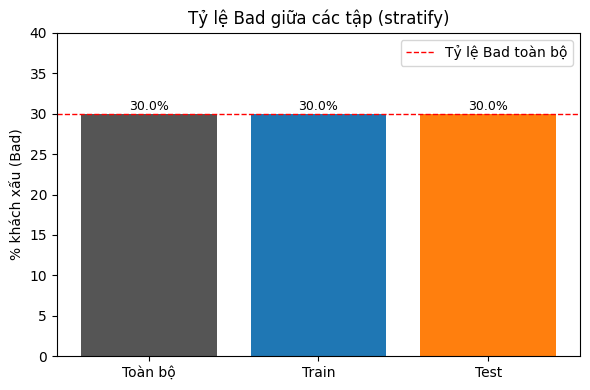

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split

SEED = 42   # dùng chung cho toàn bộ notebook (split, CV, model, bootstrap)

# 1. Dùng lại dữ liệu đã tải ở A2 (không tải lại; cần chạy A2 trước)
y_raw = y_uci["class"]

# 2. Đổi nhãn: Bad = 1, Good = 0
y = (y_raw == 2).astype(int).rename("target")

# 3. Chia train/test 80/20, stratify
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

# ---------------------------------------------------------------
# 4. Bảng kiểm tra chất lượng dữ liệu (trước khi chia)
# ---------------------------------------------------------------
quality = pd.DataFrame({
    "Giá trị": [
        X.shape[0],
        X.shape[1],
        int(X.isnull().sum().sum()),
        int(X.duplicated().sum()),
        int(pd.concat([X, y], axis=1).duplicated().sum()),
    ]
}, index=[
    "Số mẫu",
    "Số đặc trưng (cột)",
    "Giá trị Null",
    "Dòng trùng lặp (X)",
    "Dòng trùng lặp (X + y)",
])
quality.index.name = "Kiểm tra dữ liệu"
print("Chất lượng dữ liệu:")
display(quality)

# ---------------------------------------------------------------
# 5. Bảng tổng hợp train/test
# ---------------------------------------------------------------
summary = pd.DataFrame({
    "Số mẫu":   [len(y), len(y_train), len(y_test)],
    "Good (0)": [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    "Bad (1)":  [(y == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()],
}, index=["Toàn bộ", "Train", "Test"])
summary["% Bad"] = (summary["Bad (1)"] / summary["Số mẫu"] * 100).round(1)
summary["% so với toàn bộ"] = (summary["Số mẫu"] / len(y) * 100).round(1)

print("Bảng chia train/test:")
display(summary)

# ---------------------------------------------------------------
# 6. Kiểm tra không rò rỉ giữa train và test
# ---------------------------------------------------------------
overlap = len(set(X_train.index) & set(X_test.index))
print(f"Số mẫu nằm ở cả train và test (phải = 0): {overlap}")
assert overlap == 0
assert len(X_train) + len(X_test) == len(X)

# ---------------------------------------------------------------
# 7. Biểu đồ tỷ lệ Bad (kiểm tra stratify)
# ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(summary.index, summary["% Bad"],
              color=["#555555", "#1f77b4", "#ff7f0e"])
ax.axhline(y.mean() * 100, color="red", ls="--", lw=1, label="Tỷ lệ Bad toàn bộ")
for b, v in zip(bars, summary["% Bad"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center", fontsize=9)
ax.set_ylabel("% khách xấu (Bad)")
ax.set_title("Tỷ lệ Bad giữa các tập (stratify)")
ax.set_ylim(0, 40)
ax.legend()
plt.tight_layout()
plt.show()

KL: Chia 80/20 stratified, tỷ lệ Bad 30% ở cả hai tập, không trùng mẫu

## Bước 1: Pipeline tiền xử lý + mô hình

In [ ]:
import numpy as np
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (FunctionTransformer, StandardScaler,
                                   OneHotEncoder, OrdinalEncoder)
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import mutual_info_classif


# ---------------------------------------------------------------
# 1. Phân nhóm cột
# ---------------------------------------------------------------
num_cols = ["Attribute2", "Attribute5", "Attribute8", "Attribute11",
            "Attribute13", "Attribute16", "Attribute18"]
log_cols = ["Attribute5"]                                   # credit amount
plain_num_cols = [c for c in num_cols if c not in log_cols]
cat_cols = [c for c in X_train.columns if c not in num_cols]

assert set(num_cols) | set(cat_cols) == set(X_train.columns)
assert not set(num_cols) & set(cat_cols)
print("Số:", len(num_cols), "| Phân loại:", len(cat_cols))

# Chỉ số tính từ tên cột, không gõ cứng (dùng cho nhánh SMOTENC)
log_idx   = [num_cols.index(c) for c in log_cols]
plain_idx = [num_cols.index(c) for c in plain_num_cols]
cat_idx   = list(range(len(num_cols), len(num_cols) + len(cat_cols)))



Số: 7 | Phân loại: 13


### Bước 1a: Kiểm tra rò rỉ dữ liệu

In [ ]:
def check_leakage_on_train(X_train, y_train, X_test, num_cols, cat_cols,
                           seed=42, auc_threshold=0.85, mi_threshold=0.10):
    print("🔍 KIỂM TRA RÒ RỈ (CHỈ DÙNG TRAIN ĐỂ RA QUYẾT ĐỊNH) 🔍")
    print("-" * 60)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    # 1. AUC của từng cột đứng một mình
    rows = []
    for col in X_train.columns:
        enc = ("passthrough" if col in num_cols
               else OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        pipe = Pipeline([
            ("prep", ColumnTransformer([("c", enc, [col])])),
            ("tree", DecisionTreeClassifier(max_depth=3, min_samples_leaf=20,
                                            random_state=seed)),
        ])
        auc = cross_val_score(pipe, X_train, y_train, cv=skf,
                              scoring="roc_auc", n_jobs=-1).mean()
        rows.append((col, auc))
    auc_s = pd.Series(dict(rows)).sort_values(ascending=False)

    print(f"1. AUC từng cột riêng lẻ (cảnh báo > {auc_threshold}):")
    print(auc_s.head(5).round(3).to_string())
    flagged_auc = auc_s[auc_s > auc_threshold]
    print("   ⚠️ NGHI RÒ RỈ:" if not flagged_auc.empty else "   ✅ An toàn.",
          list(flagged_auc.index) if not flagged_auc.empty else "")
    print("-" * 60)

    # 2. Mutual Information (khai báo cột phân loại là rời rạc)
    X_enc = X_train.copy()
    X_enc[cat_cols] = OrdinalEncoder().fit_transform(X_train[cat_cols])
    X_enc = X_enc.astype(float)
    discrete_mask = np.array([c in cat_cols for c in X_enc.columns])
    mi = mutual_info_classif(X_enc, y_train, discrete_features=discrete_mask,
                             random_state=seed)
    mi_s = pd.Series(mi, index=X_enc.columns).sort_values(ascending=False)

    print(f"2. Mutual Information (cảnh báo > {mi_threshold}, tối đa ≈ 0.693):")
    print(mi_s.head(5).round(4).to_string())
    flagged_mi = mi_s[mi_s > mi_threshold]
    print("   ⚠️ NGHI RÒ RỈ:" if not flagged_mi.empty else "   ✅ An toàn.",
          list(flagged_mi.index) if not flagged_mi.empty else "")
    print("-" * 60)

    # 3. Trùng dòng giữa train và test (theo nội dung, không theo index)
    n_dup = X_test.merge(X_train.drop_duplicates(), how="inner").shape[0]
    print(f"3. Số dòng test trùng nội dung với train: {n_dup}")
    print("   ✅ An toàn." if n_dup == 0 else "   ⚠️ Có trùng, cần xem lại.")

    return auc_s, mi_s

auc_scores, mi_scores = check_leakage_on_train(
    X_train, y_train, X_test, num_cols, cat_cols)

🔍 KIỂM TRA RÒ RỈ (CHỈ DÙNG TRAIN ĐỂ RA QUYẾT ĐỊNH) 🔍
------------------------------------------------------------
1. AUC từng cột riêng lẻ (cảnh báo > 0.85):
Attribute1     0.700
Attribute2     0.626
Attribute3     0.621
Attribute4     0.594
Attribute12    0.588
   ✅ An toàn. 
------------------------------------------------------------
2. Mutual Information (cảnh báo > 0.1, tối đa ≈ 0.693):
Attribute1    0.0608
Attribute3    0.0273
Attribute6    0.0223
Attribute5    0.0220
Attribute4    0.0159
   ✅ An toàn. 
------------------------------------------------------------
3. Số dòng test trùng nội dung với train: 0
   ✅ An toàn.


In [ ]:
def find_droppable_cols(X_train, num_cols, cat_cols,
                        dominant_thresh=0.98, corr_thresh=0.90):
    """Trả về dict {tên cột: lý do} cho các cột nên loại. Chỉ dùng X_train, không dùng nhãn."""
    to_drop = {}

    # 1. Cột gần như hằng số: một giá trị chiếm >= 98% số dòng
    for col in X_train.columns:
        top_share = X_train[col].value_counts(normalize=True).iloc[0]
        if top_share >= dominant_thresh:
            to_drop[col] = f"gần hằng số ({top_share:.1%} cùng một giá trị)"

    # 2. Hai cột số tương quan quá cao: giữ cột đứng trước, bỏ cột đứng sau
    keep_num = [c for c in num_cols if c not in to_drop]
    corr = X_train[keep_num].corr(method="spearman").abs()
    for i, a in enumerate(keep_num):
        if a in to_drop:
            continue
        for b in keep_num[i + 1:]:
            if b not in to_drop and corr.loc[a, b] >= corr_thresh:
                to_drop[b] = f"tương quan {corr.loc[a, b]:.2f} với {a}"

    return to_drop

dropped = find_droppable_cols(X_train, num_cols, cat_cols)

if dropped:
    print("Cột sẽ loại:")
    for c, why in dropped.items():
        print(f"  - {c}: {why}")
else:
    print("✅ Không có cột nào cần loại theo quy tắc.")

# Cập nhật danh sách cột (chỉ chạy khi có cột bị loại)
num_cols        = [c for c in num_cols if c not in dropped]
log_cols        = [c for c in log_cols if c not in dropped]
plain_num_cols  = [c for c in num_cols if c not in log_cols]
cat_cols        = [c for c in cat_cols if c not in dropped]

# Tính lại chỉ số cho nhánh SMOTENC
log_idx   = [num_cols.index(c) for c in log_cols]
plain_idx = [num_cols.index(c) for c in plain_num_cols]
cat_idx   = list(range(len(num_cols), len(num_cols) + len(cat_cols)))

print("Sau khi loại -> Số:", len(num_cols), "| Phân loại:", len(cat_cols))

✅ Không có cột nào cần loại theo quy tắc.
Sau khi loại -> Số: 7 | Phân loại: 13


Với German Credit, các cột số không có cặp nào tương quan ≥ 0.90 (cặp cao nhất là Attribute2 với Attribute5, khoảng 0.6 đến 0.7), và cũng không có cột nào gần hằng số. Nên sẽ in ra “không có cột nào cần loại”.

In [ ]:
# ---------------------------------------------------------------
# 2. Các khối tiền xử lý (dùng chung cho cả hai nhánh)
# ---------------------------------------------------------------
def make_log_pipe():
    return Pipeline([
        ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
        ("scale", StandardScaler()),
    ])

def make_ohe():
    return OneHotEncoder(
        handle_unknown="infrequent_if_exist",
        min_frequency=30,
        drop="if_binary",
        sparse_output=False,
    )

preprocessor = ColumnTransformer(
    transformers=[
        ("log_num", make_log_pipe(), log_cols),
        ("num", StandardScaler(), plain_num_cols),
        ("cat", make_ohe(), cat_cols),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

# ---------------------------------------------------------------
# 3. Mô hình (n_jobs=1 bên trong, song song hóa ở cross_val_score)
# ---------------------------------------------------------------
USE_SMOTENC = False

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, random_state=SEED),
    "Neural Network": MLPClassifier(
        hidden_layer_sizes=(32,), alpha=1e-2, max_iter=1000,
        early_stopping=True, random_state=SEED),
    "Random Forest": RandomForestClassifier(
        n_estimators=500, min_samples_leaf=3, n_jobs=1, random_state=SEED),
    "SVM": SVC(kernel="rbf", probability=True, random_state=SEED),
    "KNN": KNeighborsClassifier(n_neighbors=15),
}
try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric="logloss", random_state=SEED, n_jobs=1)
except ImportError:
    print("Chưa cài xgboost, bỏ qua XGBoost.")

# ---------------------------------------------------------------
# 4. Ghép pipeline (mỗi pipeline có bản clone riêng)
# ---------------------------------------------------------------
def build_pipeline(clf, use_smotenc=False):
    if not use_smotenc:
        return Pipeline([("prep", clone(preprocessor)), ("model", clone(clf))])

    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTENC

    ord_prep = ColumnTransformer([
        ("num", "passthrough", num_cols),
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value",
                               unknown_value=-1), cat_cols),
    ], verbose_feature_names_out=False)

    post = ColumnTransformer([
        ("log_num", make_log_pipe(), log_idx),
        ("num", StandardScaler(), plain_idx),
        ("cat", make_ohe(), cat_idx),
    ])
    return ImbPipeline([
        ("ord", ord_prep),
        ("smote", SMOTENC(categorical_features=cat_idx, random_state=SEED)),
        ("post", post),
        ("model", clone(clf)),
    ])

pipelines = {name: build_pipeline(clf, USE_SMOTENC) for name, clf in models.items()}

# ---------------------------------------------------------------
# 5. Kiểm tra nhanh (CV chỉ trên train)
# ---------------------------------------------------------------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

n_feat = clone(preprocessor).fit(X_train, y_train).get_feature_names_out().shape[0]
print("Số feature sau tiền xử lý:", n_feat)

for name, pipe in pipelines.items():
    auc = cross_val_score(pipe, X_train, y_train, cv=skf,
                          scoring="roc_auc", n_jobs=-1)
    print(f"{name:20s} ROC-AUC CV: {auc.mean():.3f} ± {auc.std():.3f}")

Số feature sau tiền xử lý: 56
Logistic Regression  ROC-AUC CV: 0.769 ± 0.052
Neural Network       ROC-AUC CV: 0.696 ± 0.057
Random Forest        ROC-AUC CV: 0.794 ± 0.040
SVM                  ROC-AUC CV: 0.784 ± 0.034
KNN                  ROC-AUC CV: 0.734 ± 0.033
XGBoost              ROC-AUC CV: 0.790 ± 0.040


* Có 7 cột số (thời hạn vay, số tiền vay, tỷ lệ trả góp, thời gian cư trú, tuổi, số khoản vay hiện có, số người phụ thuộc) và 13 cột phân loại, tổng 20 cột. Khớp với German Credit nên việc phân nhóm cột đúng, không sót, không trùng.
* 13 cột phân loại sau one-hot nở thành khoảng 49 cột (nhóm hiếm gộp lại), cộng 7 cột số = 56. Con số này chỉ để kiểm tra pipeline chạy; không cần diễn giải thêm.

* Số đứng trước là trung bình AUC qua 5 fold trên tập train.
* Số sau dấu ± là độ lệch chuẩn giữa 5 fold, cho biết kết quả dao động bao nhiêu khi đổi tập validation.
* AUC là xác suất model xếp một khách Bad cao hơn một khách Good ngẫu nhiên: 0.5 là đoán bừa, 1.0 là hoàn hảo.

## Bước 2: Hàm chi phí (cost function)

In [ ]:
from sklearn.metrics import confusion_matrix

# ---------------------------------------------------------------
# 1. Ma trận chi phí
# ---------------------------------------------------------------
COST_FN = 5   # duyệt nhầm khách Bad
COST_FP = 1   # từ chối nhầm khách Good

# Ngưỡng lý thuyết: dự đoán Bad khi p*COST_FN > (1-p)*COST_FP
THEORETICAL_THRESHOLD = COST_FP / (COST_FP + COST_FN)   # = 1/6 ≈ 0.167
print(f"Ngưỡng lý thuyết: {THEORETICAL_THRESHOLD:.3f}")

# ---------------------------------------------------------------
# 2. Hàm tính cost
# ---------------------------------------------------------------
def confusion_counts(y_true, y_pred):
    """Trả về TN, FP, FN, TP (luôn đủ 4 giá trị dù thiếu lớp)."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn, fp, fn, tp

def total_cost(y_true, y_pred, cost_fp=COST_FP, cost_fn=COST_FN):
    """Tổng chi phí."""
    _, fp, fn, _ = confusion_counts(y_true, y_pred)
    return cost_fp * fp + cost_fn * fn

def avg_cost(y_true, y_pred, cost_fp=COST_FP, cost_fn=COST_FN):
    """Chi phí trung bình trên mỗi khách hàng (so sánh được giữa các tập khác cỡ)."""
    return total_cost(y_true, y_pred, cost_fp, cost_fn) / len(y_true)

def cost_at_threshold(y_true, proba, threshold, cost_fn=COST_FN, cost_fp=COST_FP):
    """Cost khi dự đoán Bad nếu proba >= threshold (cost_fn/cost_fp đổi được cho Bước 11)."""
    y_pred = (np.asarray(proba) >= threshold).astype(int)
    return total_cost(y_true, y_pred, cost_fp, cost_fn)

# ---------------------------------------------------------------
# 3. Quét ngưỡng (dùng ở Bước 7, trên OOF)
# ---------------------------------------------------------------
def threshold_sweep(y_true, proba, thresholds=None, cost_fn=COST_FN, cost_fp=COST_FP):
    """Bảng cost, FP, FN, recall, precision theo từng ngưỡng."""
    if thresholds is None:
        thresholds = np.arange(0.01, 1.00, 0.01)
    rows = []
    for t in thresholds:
        y_pred = (np.asarray(proba) >= t).astype(int)
        tn, fp, fn, tp = confusion_counts(y_true, y_pred)
        rows.append({
            "threshold": round(float(t), 3),
            "FP": fp, "FN": fn,
            "cost": cost_fp * fp + cost_fn * fn,
            "recall": tp / (tp + fn) if (tp + fn) else 0.0,
            "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        })
    return pd.DataFrame(rows)

def best_threshold(y_true, proba, thresholds=None, cost_fn=COST_FN, cost_fp=COST_FP):
    """Ngưỡng có cost thấp nhất. Nếu hòa, lấy ngưỡng ở giữa vùng hòa cho ổn định."""
    df = threshold_sweep(y_true, proba, thresholds, cost_fn, cost_fp)
    best = df["cost"].min()
    t_best = df.loc[df["cost"] == best, "threshold"].median()
    return float(t_best), int(best)

# ---------------------------------------------------------------
# 4. Cost của các baseline đơn giản (chỉ tính trên TRAIN)
# ---------------------------------------------------------------
n_train = len(y_train)
approve_all = np.zeros(n_train, dtype=int)   # dự đoán toàn Good
reject_all  = np.ones(n_train, dtype=int)    # dự đoán toàn Bad

baseline = pd.DataFrame({
    "FP": [confusion_counts(y_train, p)[1] for p in (approve_all, reject_all)],
    "FN": [confusion_counts(y_train, p)[2] for p in (approve_all, reject_all)],
    "Cost tổng": [total_cost(y_train, p) for p in (approve_all, reject_all)],
    "Cost/khách": [avg_cost(y_train, p) for p in (approve_all, reject_all)],
}, index=["Duyệt tất cả", "Từ chối tất cả"])
print(baseline)

# Kiểm tra nhanh các hàm
assert total_cost(y_train, approve_all) == COST_FN * (y_train == 1).sum()
assert total_cost(y_train, reject_all) == COST_FP * (y_train == 0).sum()

# Mốc cần vượt: baseline đơn giản tốt nhất (dùng ở Bước 3, 7, 10)
best_trivial = min(total_cost(y_train, approve_all), total_cost(y_train, reject_all))

# ---------------------------------------------------------------
# 5. KS (không phụ thuộc ngưỡng); định nghĩa ở đây vì Bước 7, 8 đều dùng
# ---------------------------------------------------------------
def ks_stat(y_true, proba):
    fpr, tpr, _ = roc_curve(y_true, proba)
    return float(np.max(tpr - fpr))


Ngưỡng lý thuyết: 0.167
                 FP   FN  Cost tổng  Cost/khách
Duyệt tất cả      0  240       1200         1.5
Từ chối tất cả  560    0        560         0.7


KL: Ma trận 5:1, ngưỡng lý thuyết 1/6, mốc “từ chối tất cả” = 0.70/khách

Ngưỡng lý thuyết: 0.167
Là ngưỡng xác suất mà tại đó duyệt hay từ chối có chi phí kỳ vọng bằng nhau.

## Bước 3: Chiến lược CV + baseline mô hình

Bảng chia 5 fold (StratifiedKFold, chỉ trên tập train):


,Train fold,Bad trong train fold,Validation fold,Bad trong validation,% Bad validation
Fold,,,,,
1,640,192,160,48,30.0
2,640,192,160,48,30.0
3,640,192,160,48,30.0
4,640,192,160,48,30.0
5,640,192,160,48,30.0


Mỗi mẫu train xuất hiện ở validation đúng 1 lần -> 800 = 800


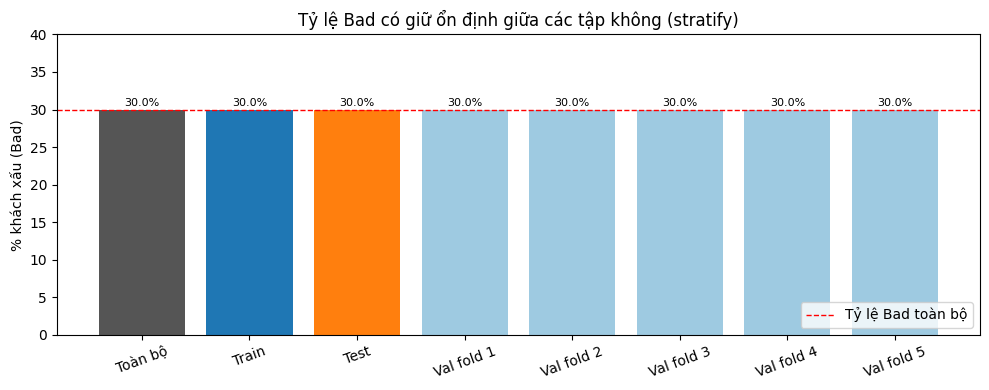

In [ ]:
N_SPLITS = 5
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

# ---------------------------------------------------------------
# 1. Bảng 5 fold
# ---------------------------------------------------------------
fold_rows, val_idx_all = [], []
for k, (tr, va) in enumerate(skf.split(X_train, y_train), 1):
    val_idx_all.extend(va)
    fold_rows.append({
        "Fold": k,
        "Train fold": len(tr),
        "Bad trong train fold": int(y_train.iloc[tr].sum()),
        "Validation fold": len(va),
        "Bad trong validation": int(y_train.iloc[va].sum()),
        "% Bad validation": round(y_train.iloc[va].mean() * 100, 1),
    })
fold_table = pd.DataFrame(fold_rows).set_index("Fold")

print(f"Bảng chia {N_SPLITS} fold (StratifiedKFold, chỉ trên tập train):")
display(fold_table)

assert sorted(val_idx_all) == list(range(len(X_train)))
print(f"Mỗi mẫu train xuất hiện ở validation đúng 1 lần -> {len(val_idx_all)} = {len(X_train)}")

# ---------------------------------------------------------------
# 2. Biểu đồ tỷ lệ Bad: toàn bộ / train / test / 5 fold
# ---------------------------------------------------------------
labels = ["Toàn bộ", "Train", "Test"] + [f"Val fold {k}" for k in fold_table.index]
values = [y.mean() * 100, y_train.mean() * 100, y_test.mean() * 100] + \
         list(fold_table["% Bad validation"])
colors = ["#555555", "#1f77b4", "#ff7f0e"] + ["#9ecae1"] * N_SPLITS

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(labels, values, color=colors)
ax.axhline(y.mean() * 100, color="red", ls="--", lw=1, label="Tỷ lệ Bad toàn bộ")
for b, v in zip(bars, values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.5, f"{v:.1f}%", ha="center", fontsize=8)
ax.set_ylabel("% khách xấu (Bad)")
ax.set_title("Tỷ lệ Bad có giữ ổn định giữa các tập không (stratify)")
ax.set_ylim(0, 40); ax.legend(loc="lower right")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()

In [ ]:
# ---------------------------------------------------------------
# 3. OOF proba cho 6 model (mặc định, chưa tune)
# ---------------------------------------------------------------
oof_proba_base = {}
base_rows = []

for name, pipe in pipelines.items():
    t0 = time.time()
    # cross_val_predict tự clone pipeline và fit lại trên từng train fold
    proba = cross_val_predict(
        clone(pipe), X_train, y_train, cv=skf,
        method="predict_proba", n_jobs=-1,
    )[:, 1]
    oof_proba_base[name] = proba

    # Ba chiến lược ngưỡng, tất cả đều tính trên OOF của train
    t_opt, cost_opt = best_threshold(y_train, proba)
    cost_05   = cost_at_threshold(y_train, proba, 0.5)
    cost_theo = cost_at_threshold(y_train, proba, THEORETICAL_THRESHOLD)

    base_rows.append({
        "Model": name,
        "AUC OOF": roc_auc_score(y_train, proba),
        "Cost @0.5": cost_05,
        "Cost @1/6": cost_theo,
        "Ngưỡng tối ưu": t_opt,
        "Cost @tối ưu": cost_opt,
        "Cost/khách @tối ưu": cost_opt / len(y_train),
        "Thời gian (s)": round(time.time() - t0, 1),
    })

baseline_models = (pd.DataFrame(base_rows)
                   .set_index("Model")
                   .sort_values("Cost @tối ưu"))
view = baseline_models[["AUC OOF", "Cost @0.5", "Cost @1/6", "Ngưỡng tối ưu",
                        "Cost @tối ưu", "Cost/khách @tối ưu", "Thời gian (s)"]]
print("Baseline 6 model (OOF trên train, chưa tune), xếp theo cost tối ưu:")
display(
    view.style
        .format({"AUC OOF": "{:.3f}", "Ngưỡng tối ưu": "{:.2f}",
                 "Cost/khách @tối ưu": "{:.3f}", "Thời gian (s)": "{:.1f}"})
        .highlight_min(subset=["Cost @0.5", "Cost @1/6", "Cost @tối ưu",
                               "Cost/khách @tối ưu"], color="#c7e9c0")
        .highlight_max(subset=["AUC OOF"], color="#c7e9c0")
)

# ---------------------------------------------------------------
# 4. So với baseline đơn giản
# ---------------------------------------------------------------
print(f"\nMốc cần vượt (từ chối tất cả): {best_trivial} "
      f"({best_trivial/len(y_train):.2f}/khách)")
print("Model tốt hơn mốc này (tại ngưỡng tối ưu OOF):",
      list(baseline_models.index[baseline_models["Cost @tối ưu"] < best_trivial]))


Baseline 6 model (OOF trên train, chưa tune), xếp theo cost tối ưu:


,AUC OOF,Cost @0.5,Cost @1/6,Ngưỡng tối ưu,Cost @tối ưu,Cost/khách @tối ưu,Thời gian (s)
Model,,,,,,,
XGBoost,0.789,682,448,0.10,407,0.509,1.9
Random Forest,0.793,805,430,0.14,424,0.530,5.7
Logistic Regression,0.768,730,438,0.12,433,0.541,0.3
SVM,0.779,752,457,0.19,447,0.559,1.5
KNN,0.734,1035,476,0.17,476,0.595,0.5
Neural Network,0.700,1075,522,0.19,479,0.599,0.6



Mốc cần vượt (từ chối tất cả): 560 (0.70/khách)
Model tốt hơn mốc này (tại ngưỡng tối ưu OOF): ['XGBoost', 'Random Forest', 'Logistic Regression', 'SVM', 'KNN', 'Neural Network']


AUC OOF: Khả năng xếp khách Bad cao hơn Good, tính trên 800 dự đoán gộp lại. Không phụ thuộc ngưỡng

KL: Cả 6 model đều vượt mốc 0.70; chưa tune nên chưa kết luận về model

## Bước 4: Tối ưu siêu tham số (GridSearchCV cho 6 model)

In [ ]:
from sklearn.model_selection import GridSearchCV

# ---------------------------------------------------------------
# 1. Lưới tham số (tiền tố model__ vì model nằm trong Pipeline)
# ---------------------------------------------------------------
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10],
    },
    "Random Forest": {
        "model__n_estimators": [300],
        "model__max_depth": [4, 8, None],
        "model__min_samples_leaf": [3, 5, 10],
        "model__max_features": ["sqrt", 0.3],
    },
    "XGBoost": {
        "model__n_estimators": [150, 300],
        "model__learning_rate": [0.03, 0.05, 0.1],
        "model__max_depth": [2, 3, 4],
        "model__colsample_bytree": [0.6, 0.8],
    },
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.01, 0.03],
    },
    "KNN": {
        "model__n_neighbors": [5, 11, 15, 21, 31, 41],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
    "Neural Network": {
        "model__hidden_layer_sizes": [(16,), (32,), (64,)],
        "model__alpha": [1e-3, 1e-2, 1e-1, 1.0],
        "model__learning_rate_init": [1e-3, 1e-2],
    },
}

# ---------------------------------------------------------------
# 2. CV riêng cho việc tune (seed khác với skf dùng cho OOF ở Bước 6)
# ---------------------------------------------------------------
tune_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED + 1)

scoring = {"roc_auc": "roc_auc", "neg_log_loss": "neg_log_loss"}

# ---------------------------------------------------------------
# 3. Chạy GridSearchCV cho từng model (chỉ trên X_train, y_train)
# ---------------------------------------------------------------
grid_results = {}    # name -> GridSearchCV đã fit (refit trên toàn bộ train)
tune_rows = []

for name, pipe in pipelines.items():
    t0 = time.time()
    pipe = clone(pipe)
    # Tránh oversubscription: song song hóa ở mức GridSearchCV, không phải trong model
    if "n_jobs" in pipe.named_steps["model"].get_params():
        pipe.set_params(model__n_jobs=1)

    gs = GridSearchCV(
        estimator=pipe,
        param_grid=param_grids[name],
        scoring=scoring,
        refit="roc_auc",          # chọn tham số theo AUC, refit trên toàn bộ train
        cv=tune_cv,
        n_jobs=-1,
        return_train_score=False,
    )
    gs.fit(X_train, y_train)
    grid_results[name] = gs

    i = gs.best_index_
    n_combo = len(gs.cv_results_["params"])
    tune_rows.append({
        "Model": name,
        "Số tổ hợp": n_combo,
        "AUC CV (tune)": gs.cv_results_["mean_test_roc_auc"][i],
        "Std AUC": gs.cv_results_["std_test_roc_auc"][i],
        "Log-loss CV": -gs.cv_results_["mean_test_neg_log_loss"][i],
        "Best params": {k.replace("model__", ""): v for k, v in gs.best_params_.items()},
        "Thời gian (s)": round(time.time() - t0, 1),
    })
    print(f"[xong] {name:20s} AUC={gs.best_score_:.3f}  ({time.time()-t0:.0f}s)")

tuning_table = pd.DataFrame(tune_rows).set_index("Model").sort_values(
    "AUC CV (tune)", ascending=False)

# ---------------------------------------------------------------
# 4. Bảng kết quả tune
# ---------------------------------------------------------------
print("\nKết quả tune siêu tham số (theo ROC-AUC, CV trên train):")
display(
    tuning_table.style
        .format({"AUC CV (tune)": "{:.3f}", "Std AUC": "{:.3f}",
                 "Log-loss CV": "{:.3f}", "Thời gian (s)": "{:.1f}"})
        .highlight_max(subset=["AUC CV (tune)"], color="#c7e9c0")
        .highlight_min(subset=["Log-loss CV"], color="#c7e9c0")
)


[xong] Logistic Regression  AUC=0.776  (4s)
[xong] Neural Network       AUC=0.770  (17s)
[xong] Random Forest        AUC=0.785  (68s)
[xong] SVM                  AUC=0.765  (8s)
[xong] KNN                  AUC=0.760  (7s)
[xong] XGBoost              AUC=0.784  (20s)

Kết quả tune siêu tham số (theo ROC-AUC, CV trên train):


,Số tổ hợp,AUC CV (tune),Std AUC,Log-loss CV,Best params,Thời gian (s)
Model,,,,,,
Random Forest,18,0.785,0.050,0.509,"{'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'n_estimators': 300}",68.5
XGBoost,36,0.784,0.052,0.502,"{'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 150}",20.3
Logistic Regression,7,0.776,0.056,0.516,{'C': 0.03},4.1
Neural Network,24,0.770,0.046,0.525,"{'alpha': 0.001, 'hidden_layer_sizes': (32,), 'learning_rate_init': 0.01}",17.2
SVM,9,0.765,0.050,0.520,"{'C': 1, 'gamma': 0.03}",7.5
KNN,24,0.760,0.029,0.522,"{'n_neighbors': 21, 'p': 1, 'weights': 'distance'}",7.3


KL: Tham số tốt nhất của 6 model. Random Forest và XGBoost đứng đầu (AUC CV 0.785 và 0.784), nhưng Std ≈ 0.05 nên các model chưa tách nhau được. Tác dụng của việc tune được so sánh đúng cách ở Bước 6 (cùng OOF, cùng skf).

## Bước 5: Huấn luyện lại model tối ưu trên toàn bộ train

In [ ]:
from sklearn.utils.validation import check_is_fitted

# ---------------------------------------------------------------
# 1. Lấy 6 model đã refit trên TOÀN BỘ train (800 mẫu)
# ---------------------------------------------------------------
best_estimators = {name: gs.best_estimator_ for name, gs in grid_results.items()}

# ---------------------------------------------------------------
# 2. Kiểm tra: đã fit, đúng tham số, đúng số feature
# ---------------------------------------------------------------
check_rows = []
for name, est in best_estimators.items():
    check_is_fitted(est)
    n_feat = len(est.named_steps["prep"].get_feature_names_out())
    # so khớp tham số đã chọn với tham số thực của model trong pipeline
    chosen = grid_results[name].best_params_
    ok = all(est.get_params()[k] == v for k, v in chosen.items())
    check_rows.append({
        "Model": name,
        "Đã fit": True,
        "Số feature sau tiền xử lý": n_feat,
        "Tham số khớp": "✔" if ok else "✘",
        "AUC CV (tune)": grid_results[name].best_score_,
    })
    assert ok, f"Tham số của {name} không khớp!"

check_table = pd.DataFrame(check_rows).set_index("Model")
print("Bước 5: 6 model tối ưu, đã huấn luyện lại trên toàn bộ train "
      f"({len(X_train)} mẫu):")
display(check_table.sort_values("AUC CV (tune)", ascending=False)
        .style.format({"AUC CV (tune)": "{:.3f}"}))

# ---------------------------------------------------------------
# 3. Bảng tham số tốt nhất, dạng cột để dễ đọc
# ---------------------------------------------------------------
params_long = []
for name, gs in grid_results.items():
    for k, v in gs.best_params_.items():
        params_long.append({"Model": name,
                            "Tham số": k.replace("model__", ""),
                            "Giá trị": str(v)})
params_table = pd.DataFrame(params_long).set_index(["Model", "Tham số"])
display(params_table)

# ---------------------------------------------------------------
# 4. Sanity check: xác suất trên train (in-sample) CHỈ để kiểm tra
#    model chạy được, KHÔNG dùng để tune ngưỡng hay đánh giá
# ---------------------------------------------------------------
sanity = {name: est.predict_proba(X_train.head(5))[:, 1].round(3)
          for name, est in best_estimators.items()}
print("Xác suất Bad của 5 khách đầu tiên (chỉ để kiểm tra model chạy):")
display(pd.DataFrame(sanity, index=[f"Khách {i+1}" for i in range(5)]))

Bước 5: 6 model tối ưu, đã huấn luyện lại trên toàn bộ train (800 mẫu):


,Đã fit,Số feature sau tiền xử lý,Tham số khớp,AUC CV (tune)
Model,,,,
Random Forest,True,56,✔,0.785
XGBoost,True,56,✔,0.784
Logistic Regression,True,56,✔,0.776
Neural Network,True,56,✔,0.770
SVM,True,56,✔,0.765
KNN,True,56,✔,0.760


Giá trị
Model               Tham số                     
Logistic Regression C                       0.03
Neural Network      alpha                  0.001
                    hidden_layer_sizes     (32,)
                    learning_rate_init      0.01
Random Forest       max_depth                  8
                    max_features            sqrt
                    min_samples_leaf           3
                    n_estimators             300
SVM                 C                          1
                    gamma                   0.03
KNN                 n_neighbors               21
                    p                          1
                    weights             distance
XGBoost             colsample_bytree         0.8
                    learning_rate           0.05
                    max_depth                  3
                    n_estimators             150

Xác suất Bad của 5 khách đầu tiên (chỉ để kiểm tra model chạy):


,Logistic Regression,Neural Network,Random Forest,SVM,KNN,XGBoost
Khách 1,0.389,0.279,0.536,0.428,1.0,0.558
Khách 2,0.149,0.011,0.095,0.130,0.0,0.095
Khách 3,0.396,0.143,0.362,0.336,0.0,0.377
Khách 4,0.631,0.163,0.374,0.638,0.0,0.449
Khách 5,0.423,0.222,0.336,0.273,0.0,0.326


Lưu ý khi đọc bảng xác suất ở trên: KNN cho đúng 1.000 / 0.000 vì đây là dự đoán trên chính dữ liệu train (in-sample) với `weights="distance"`: khách đang xét là láng giềng gần nhất của chính nó (khoảng cách 0). Đây không phải lỗi, và cũng không phản ánh chất lượng thật của KNN; chất lượng thật được đo ở OOF (Bước 6, 7) và test (Bước 8).

## Bước 6: Xác suất OOF của 6 model đã tune

In [ ]:
# Dùng lại skf (seed 42), khác tune_cv (seed 43) đã dùng để chọn tham số.
# clone() giữ nguyên tham số tốt nhất nhưng bỏ trạng thái đã fit,
# nên mỗi fold được fit lại từ đầu, chỉ trên train fold.
oof_proba = {}
for name, est in best_estimators.items():
    t0 = time.time()
    oof_proba[name] = cross_val_predict(
        clone(est), X_train, y_train, cv=skf,
        method="predict_proba", n_jobs=-1,
    )[:, 1]
    print(f"[xong] {name:20s} {time.time()-t0:.0f}s")

# Kiểm tra: đủ 800 dự đoán, nằm trong [0, 1], không có NaN
oof_df = pd.DataFrame(oof_proba, index=X_train.index)
assert oof_df.shape == (len(X_train), 6)
assert oof_df.notna().all().all() and oof_df.min().min() >= 0 and oof_df.max().max() <= 1

print("\nBước 6: xác suất OOF (mỗi khách được dự đoán bởi model chưa thấy khách đó)")
display(oof_df.describe().T[["mean", "min", "50%", "max"]]
        .rename(columns={"mean": "TB xác suất", "min": "Min", "50%": "Trung vị", "max": "Max"})
        .style.format("{:.3f}"))
print(f"Tỷ lệ Bad thực tế trong train: {y_train.mean():.3f} "
      "(TB xác suất gần giá trị này chỉ cho biết hiệu chuẩn trung bình, chưa phải hiệu chuẩn ở từng mức xác suất)")

[xong] Logistic Regression  0s
[xong] Neural Network       0s
[xong] Random Forest        4s
[xong] SVM                  1s
[xong] KNN                  0s
[xong] XGBoost              1s

Bước 6: xác suất OOF (mỗi khách được dự đoán bởi model chưa thấy khách đó)


,TB xác suất,Min,Trung vị,Max
Logistic Regression,0.300,0.035,0.274,0.776
Neural Network,0.317,0.007,0.279,0.967
Random Forest,0.299,0.027,0.294,0.710
SVM,0.305,0.019,0.249,0.951
KNN,0.259,0.000,0.232,0.797
XGBoost,0.296,0.010,0.247,0.887


Tỷ lệ Bad thực tế trong train: 0.300 (TB xác suất gần giá trị này chỉ cho biết hiệu chuẩn trung bình, chưa phải hiệu chuẩn ở từng mức xác suất)


### Tác dụng của việc tune (so cùng thước đo)
Trước tune (Bước 3) và sau tune (Bước 6) đều là AUC và cost gộp OOF trên cùng `skf` (seed 42), nên so sánh được trực tiếp. Bảng này thay cho bảng trước/sau ở Bước 4 (hai phía khác cách đo).

In [ ]:
# ---------------------------------------------------------------
# So sánh trước/sau tune trên CÙNG thước đo: AUC và cost gộp OOF, cùng skf (seed 42)
# ---------------------------------------------------------------
cmp_rows = []
for name in oof_proba:
    auc_b = roc_auc_score(y_train, oof_proba_base[name])
    auc_a = roc_auc_score(y_train, oof_proba[name])
    _, cost_b = best_threshold(y_train, oof_proba_base[name])
    _, cost_a = best_threshold(y_train, oof_proba[name])
    cmp_rows.append({
        "Model": name,
        "AUC trước tune": auc_b, "AUC sau tune": auc_a, "Chênh AUC": auc_a - auc_b,
        "Cost trước (ngưỡng tối ưu)": cost_b, "Cost sau (ngưỡng tối ưu)": cost_a,
        "Chênh cost": cost_a - cost_b,
    })
tune_effect = (pd.DataFrame(cmp_rows).set_index("Model")
               .sort_values("AUC sau tune", ascending=False))

print("Trước/sau tune (OOF gộp trên train, cùng skf):")
display(
    tune_effect.style
        .format({"AUC trước tune": "{:.3f}", "AUC sau tune": "{:.3f}",
                 "Chênh AUC": "{:+.3f}", "Chênh cost": "{:+d}"})
        .highlight_max(subset=["Chênh AUC"], color="#c7e9c0")
        .highlight_min(subset=["Chênh cost"], color="#c7e9c0")
)


Trước/sau tune (OOF gộp trên train, cùng skf):


,AUC trước tune,AUC sau tune,Chênh AUC,Cost trước (ngưỡng tối ưu),Cost sau (ngưỡng tối ưu),Chênh cost
Model,,,,,,
XGBoost,0.789,0.796,+0.007,407,405,-2
Random Forest,0.793,0.794,+0.001,424,419,-5
SVM,0.779,0.781,+0.002,447,441,-6
Logistic Regression,0.768,0.778,+0.010,433,412,-21
KNN,0.734,0.771,+0.037,476,430,-46
Neural Network,0.700,0.752,+0.052,479,450,-29


## Bước 7: Tìm ngưỡng tối ưu trên OOF

In [ ]:
HL = "background-color:#c7e9c0;color:black;font-weight:bold"   # tô sáng, dùng cho các bảng từ Bước 9

thresholds = np.arange(0.01, 1.00, 0.01)
n = len(y_train)
TOL = 0.02   # "vùng phẳng": ngưỡng có cost không hơn cực tiểu quá 2%

rows, sweeps = [], {}
for name, proba in oof_proba.items():
    sw = threshold_sweep(y_train, proba, thresholds)
    sweeps[name] = sw

    min_cost = sw["cost"].min()
    t_opt = sw.loc[sw["cost"] == min_cost, "threshold"].median()
    flat = sw.loc[sw["cost"] <= min_cost * (1 + TOL), "threshold"]

    # Chỉ số tại ngưỡng tối ưu
    p_opt = (proba >= t_opt).astype(int)
    tn, fp, fn, tp = confusion_counts(y_train, p_opt)

    rows.append({
        "Model": name,
        "AUC OOF": roc_auc_score(y_train, proba),
        "Cost @0.5": cost_at_threshold(y_train, proba, 0.5),
        "Cost @1/6": cost_at_threshold(y_train, proba, THEORETICAL_THRESHOLD),
        "Ngưỡng tối ưu": t_opt,
        "Cost @tối ưu": int(total_cost(y_train, p_opt)),
        "Cost/khách": total_cost(y_train, p_opt) / n,
        "Vùng phẳng": f"{flat.min():.2f} - {flat.max():.2f}",
        "FP": fp, "FN": fn,
        "Recall": tp / (tp + fn),
        "Precision": tp / (tp + fp),
        "Gini OOF": 2 * roc_auc_score(y_train, proba) - 1,
        "KS OOF": ks_stat(y_train, proba),
    })

threshold_table = (pd.DataFrame(rows).set_index("Model")
                   .sort_values("Cost @tối ưu"))

# ---------------------------------------------------------------
# Bảng 1: So sánh COST theo 3 chiến lược ngưỡng
# ---------------------------------------------------------------
cost_cols = ["Cost @0.5", "Cost @1/6", "Ngưỡng tối ưu", "Vùng phẳng",
             "Cost @tối ưu", "Cost/khách"]
cost_tbl = threshold_table[cost_cols].copy()
cost_tbl["Tiết kiệm vs từ chối tất cả"] = 1 - cost_tbl["Cost @tối ưu"] / best_trivial

print(f"Bảng 7a: So sánh chi phí theo ngưỡng (OOF, train). "
      f"Mốc 'từ chối tất cả' = {best_trivial} ({best_trivial/n:.2f}/khách)")
display(
    cost_tbl.style
        .format({"Ngưỡng tối ưu": "{:.2f}", "Cost/khách": "{:.3f}",
                 "Tiết kiệm vs từ chối tất cả": "{:.1%}"})
        .highlight_min(subset=["Cost @0.5", "Cost @1/6", "Cost @tối ưu", "Cost/khách"],
                       color="#c7e9c0")
        .highlight_max(subset=["Tiết kiệm vs từ chối tất cả"], color="#c7e9c0")
)

# ---------------------------------------------------------------
# Bảng 2: Chỉ số phân loại tại NGƯỠNG TỐI ƯU
# ---------------------------------------------------------------
metric_cols = ["Ngưỡng tối ưu", "FP", "FN", "Recall", "Precision",
               "AUC OOF", "Gini OOF", "KS OOF"]
metric_tbl = threshold_table[metric_cols].copy()
metric_tbl["F1"] = (2 * metric_tbl["Precision"] * metric_tbl["Recall"]
                    / (metric_tbl["Precision"] + metric_tbl["Recall"]))
metric_tbl = metric_tbl[["Ngưỡng tối ưu", "FP", "FN", "Recall", "Precision", "F1",
                         "AUC OOF", "Gini OOF", "KS OOF"]]

print("Bảng 7b: Recall, Precision và chỉ số xếp hạng tại ngưỡng tối ưu (OOF, train)")
display(
    metric_tbl.style
        .format({"Ngưỡng tối ưu": "{:.2f}", "Recall": "{:.1%}", "Precision": "{:.1%}",
                 "F1": "{:.3f}", "AUC OOF": "{:.3f}", "Gini OOF": "{:.3f}",
                 "KS OOF": "{:.3f}"})
        .highlight_min(subset=["FP", "FN"], color="#c7e9c0")
        .highlight_max(subset=["Recall", "Precision", "F1", "AUC OOF", "Gini OOF", "KS OOF"],
                       color="#c7e9c0")
)

# ---------------------------------------------------------------
# Chốt lựa chọn (chỉ dựa trên OOF, TRƯỚC khi nhìn test)
# ---------------------------------------------------------------
final_choice = {
    name: {"opt": float(threshold_table.loc[name, "Ngưỡng tối ưu"]),
           "theo": THEORETICAL_THRESHOLD, "default": 0.5}
    for name in threshold_table.index
}
top = threshold_table.index[0]
print(f"Model có cost OOF thấp nhất: {top} "
      f"(ngưỡng {final_choice[top]['opt']:.2f}, "
      f"{threshold_table.loc[top, 'Cost/khách']:.3f}/khách)")

Bảng 7a: So sánh chi phí theo ngưỡng (OOF, train). Mốc 'từ chối tất cả' = 560 (0.70/khách)


,Cost @0.5,Cost @1/6,Ngưỡng tối ưu,Vùng phẳng,Cost @tối ưu,Cost/khách,Tiết kiệm vs từ chối tất cả
Model,,,,,,,
XGBoost,726,431,0.15,0.14 - 0.15,405,0.506,27.7%
Logistic Regression,924,464,0.21,0.20 - 0.22,412,0.515,26.4%
Random Forest,871,433,0.16,0.16 - 0.23,419,0.524,25.2%
KNN,963,436,0.14,0.13 - 0.18,430,0.537,23.2%
SVM,758,453,0.19,0.15 - 0.21,441,0.551,21.3%
Neural Network,786,453,0.19,0.16 - 0.20,450,0.562,19.6%


Bảng 7b: Recall, Precision và chỉ số xếp hạng tại ngưỡng tối ưu (OOF, train)


,Ngưỡng tối ưu,FP,FN,Recall,Precision,F1,AUC OOF,Gini OOF,KS OOF
Model,,,,,,,,,
XGBoost,0.15,295,22,90.8%,42.5%,0.579,0.796,0.592,0.474
Logistic Regression,0.21,317,19,92.1%,41.1%,0.568,0.778,0.556,0.430
Random Forest,0.16,379,8,96.7%,38.0%,0.545,0.794,0.588,0.448
KNN,0.14,345,17,92.9%,39.3%,0.552,0.771,0.542,0.411
SVM,0.19,276,33,86.2%,42.9%,0.573,0.781,0.561,0.439
Neural Network,0.19,320,26,89.2%,40.1%,0.553,0.752,0.504,0.396


Model có cost OOF thấp nhất: XGBoost (ngưỡng 0.15, 0.506/khách)


KL: Ngưỡng tối ưu từng model (0.14-0.21), gần 1/6, vùng phẳng, cost OOF

KL (đối chiếu với Bảng Bước 3 và Bảng 7b): khi so cùng thước đo thì tune không làm model nào tệ đi. AUC OOF tăng ở cả 6 model: Neural Network 0.700 lên 0.752, KNN 0.734 lên 0.771, Logistic Regression 0.768 lên 0.778, còn XGBoost, Random Forest, SVM tăng rất ít (+0.007, +0.001, +0.002) vì cấu hình mặc định đã gần tối ưu. Các giá trị âm ở bảng cũ của Bước 4 chỉ do hai phía đo khác nhau. Lưu ý: tham số được chọn trên chính tập train này (khác seed chia fold), nên mức cải thiện vẫn hơi lạc quan; con số công bằng là ở test (Bước 8).

## Bước 8: Đánh giá test

In [ ]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             matthews_corrcoef, average_precision_score,
                             brier_score_loss, log_loss, roc_curve)

# ---------------------------------------------------------------
# 1. Xác suất trên TEST (lần đầu và duy nhất dùng X_test)
#    Model đã refit trên toàn bộ train ở Bước 5
# ---------------------------------------------------------------
test_proba = {name: est.predict_proba(X_test)[:, 1]
              for name, est in best_estimators.items()}

n_test = len(y_test)
base_approve = total_cost(y_test, np.zeros(n_test, dtype=int))   # 300
base_reject  = total_cost(y_test, np.ones(n_test, dtype=int))    # 140
best_trivial_test = min(base_approve, base_reject)
print(f"Baseline test: duyệt tất cả = {base_approve} ({base_approve/n_test:.2f}/khách), "
      f"từ chối tất cả = {base_reject} ({base_reject/n_test:.2f}/khách)")

# ---------------------------------------------------------------
# 2. Chỉ số KHÔNG phụ thuộc ngưỡng
# ---------------------------------------------------------------
# ks_stat đã được định nghĩa ở Bước 2

free_rows = []
for name, p in test_proba.items():
    auc = roc_auc_score(y_test, p)
    free_rows.append({
        "Model": name,
        "AUC": auc,
        "Gini": 2 * auc - 1,
        "KS": ks_stat(y_test, p),
        "PR-AUC": average_precision_score(y_test, p),
        "Brier": brier_score_loss(y_test, p),
        "Log-loss": log_loss(y_test, p),
    })
free_table = pd.DataFrame(free_rows).set_index("Model").sort_values("Gini", ascending=False)

print("\nBước 8a: chỉ số không phụ thuộc ngưỡng (TEST)")
display(free_table.style
        .format("{:.3f}")
        .highlight_max(subset=["AUC", "Gini", "KS", "PR-AUC"], color="#c7e9c0")
        .highlight_min(subset=["Brier", "Log-loss"], color="#c7e9c0"))

# ---------------------------------------------------------------
# 3. Chỉ số PHỤ THUỘC ngưỡng: 3 chiến lược (ngưỡng đã chốt từ OOF)
# ---------------------------------------------------------------
STRATEGIES = {"default": "Ngưỡng 0.5", "theo": "Ngưỡng 1/6", "opt": "Ngưỡng tối ưu OOF"}

def eval_at(y_true, proba, t):
    pred = (np.asarray(proba) >= t).astype(int)
    tn, fp, fn, tp = confusion_counts(y_true, pred)
    rec  = tp / (tp + fn)
    spec = tn / (tn + fp)
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    cost = COST_FP * fp + COST_FN * fn
    return {
        "Ngưỡng": t, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced Acc": balanced_accuracy_score(y_true, pred),
        "Recall": rec, "Specificity": spec, "Precision": prec,
        "F1": f1, "MCC": matthews_corrcoef(y_true, pred),
        "Cost": cost, "Cost/khách": cost / len(y_true),
        "Tiết kiệm vs từ chối tất cả": 1 - cost / best_trivial_test,
    }

rows = []
for name, p in test_proba.items():
    for key, label in STRATEGIES.items():
        r = eval_at(y_test, p, final_choice[name][key])
        rows.append({"Model": name, "Chiến lược": label, **r})
test_table = pd.DataFrame(rows).set_index(["Model", "Chiến lược"])

fmt = {"Ngưỡng": "{:.2f}", "Accuracy": "{:.3f}", "Balanced Acc": "{:.3f}",
       "Recall": "{:.1%}", "Specificity": "{:.1%}", "Precision": "{:.1%}",
       "F1": "{:.3f}", "MCC": "{:.3f}", "Cost/khách": "{:.3f}",
       "Tiết kiệm vs từ chối tất cả": "{:.1%}"}

print("\nBước 8b: chỉ số tại ngưỡng tối ưu OOF (TEST)")
opt_view = test_table.xs("Ngưỡng tối ưu OOF", level="Chiến lược")
display(opt_view.style.format(fmt)
        .highlight_min(subset=["Cost", "Cost/khách"], color="#c7e9c0")
        .highlight_max(subset=["Accuracy", "Recall", "Precision", "F1", "MCC"], color="#c7e9c0"))

print("Bước 8c: cost/khách của cả 3 chiến lược ngưỡng (TEST)")
cost_view = test_table["Cost/khách"].unstack("Chiến lược")[list(STRATEGIES.values())]
cost_view["OOF @tối ưu (so sánh)"] = threshold_table["Cost/khách"]
cost_view["Chênh test - OOF"] = cost_view["Ngưỡng tối ưu OOF"] - cost_view["OOF @tối ưu (so sánh)"]
display(cost_view.sort_values("Ngưỡng tối ưu OOF").style.format("{:.3f}"))

# ---------------------------------------------------------------
# 4. Bootstrap khoảng tin cậy 95% cho cost/khách (test chỉ 200 mẫu, rất nhiễu)
# ---------------------------------------------------------------
rng = np.random.default_rng(SEED)
B = 2000
y_arr = y_test.to_numpy()
boot_idx = rng.integers(0, n_test, size=(B, n_test))

def per_sample_cost(y_true, pred):
    return np.where((y_true == 1) & (pred == 0), COST_FN,
           np.where((y_true == 0) & (pred == 1), COST_FP, 0))

reject_cost = per_sample_cost(y_arr, np.ones(n_test, dtype=int))

ci_rows = []
for name, p in test_proba.items():
    pred = (p >= final_choice[name]["opt"]).astype(int)
    c = per_sample_cost(y_arr, pred)
    boot = c[boot_idx].mean(axis=1)
    diff = (reject_cost[boot_idx].mean(axis=1) - boot)   # >0: model tốt hơn "từ chối tất cả"
    ci_rows.append({
        "Model": name,
        "Cost/khách": c.mean(),
        "CI 95% thấp": np.percentile(boot, 2.5),
        "CI 95% cao": np.percentile(boot, 97.5),
        "P(tốt hơn từ chối tất cả)": (diff > 0).mean(),
    })
ci_table = pd.DataFrame(ci_rows).set_index("Model").sort_values("Cost/khách")
print("Bước 8d: khoảng tin cậy bootstrap (ngưỡng tối ưu OOF, TEST)")
display(ci_table.style.format({"Cost/khách": "{:.3f}", "CI 95% thấp": "{:.3f}",
                               "CI 95% cao": "{:.3f}", "P(tốt hơn từ chối tất cả)": "{:.1%}"}))


Baseline test: duyệt tất cả = 300 (1.50/khách), từ chối tất cả = 140 (0.70/khách)

Bước 8a: chỉ số không phụ thuộc ngưỡng (TEST)


,AUC,Gini,KS,PR-AUC,Brier,Log-loss
Model,,,,,,
XGBoost,0.803,0.606,0.498,0.663,0.157,0.478
Random Forest,0.800,0.601,0.483,0.644,0.165,0.499
Logistic Regression,0.796,0.592,0.531,0.655,0.163,0.500
SVM,0.782,0.564,0.483,0.640,0.162,0.496
Neural Network,0.780,0.560,0.502,0.587,0.177,0.565
KNN,0.767,0.534,0.433,0.613,0.170,0.510



Bước 8b: chỉ số tại ngưỡng tối ưu OOF (TEST)


,Ngưỡng,TN,FP,FN,TP,Accuracy,Balanced Acc,Recall,Specificity,Precision,F1,MCC,Cost,Cost/khách,Tiết kiệm vs từ chối tất cả
Model,,,,,,,,,,,,,,,
Logistic Regression,0.21,62,78,8,52,0.570,0.655,86.7%,44.3%,40.0%,0.547,0.297,118,0.590,15.7%
Neural Network,0.19,86,54,11,49,0.675,0.715,81.7%,61.4%,47.6%,0.601,0.395,109,0.545,22.1%
Random Forest,0.16,41,99,2,58,0.495,0.630,96.7%,29.3%,36.9%,0.535,0.289,109,0.545,22.1%
SVM,0.19,66,74,9,51,0.585,0.661,85.0%,47.1%,40.8%,0.551,0.304,119,0.595,15.0%
KNN,0.14,42,98,6,54,0.480,0.600,90.0%,30.0%,35.5%,0.509,0.215,128,0.640,8.6%
XGBoost,0.15,63,77,6,54,0.585,0.675,90.0%,45.0%,41.2%,0.565,0.337,107,0.535,23.6%


Bước 8c: cost/khách của cả 3 chiến lược ngưỡng (TEST)


Chiến lược,Ngưỡng 0.5,Ngưỡng 1/6,Ngưỡng tối ưu OOF,OOF @tối ưu (so sánh),Chênh test - OOF
Model,,,,,
XGBoost,0.825,0.505,0.535,0.506,0.029
Random Forest,0.995,0.525,0.545,0.524,0.021
Neural Network,0.860,0.570,0.545,0.562,-0.017
Logistic Regression,1.050,0.605,0.590,0.515,0.075
SVM,0.875,0.600,0.595,0.551,0.044
KNN,1.035,0.630,0.640,0.537,0.103


Bước 8d: khoảng tin cậy bootstrap (ngưỡng tối ưu OOF, TEST)


,Cost/khách,CI 95% thấp,CI 95% cao,P(tốt hơn từ chối tất cả)
Model,,,,
XGBoost,0.535,0.415,0.665,98.7%
Neural Network,0.545,0.390,0.715,93.8%
Random Forest,0.545,0.455,0.640,99.9%
Logistic Regression,0.590,0.450,0.740,91.1%
SVM,0.595,0.455,0.745,87.9%
KNN,0.640,0.520,0.775,80.3%


KL:  Cost test, CI bootstrap, Gini, Recall/Precision, lưu ý Accuracy thấp là có chủ đích

## Bước 9: Tổng hợp và trực quan hóa 6 model

In [ ]:
OPT, THEO = "Ngưỡng tối ưu OOF", "Ngưỡng 1/6"
order = list(threshold_table.index)          # xếp theo cost OOF (tiêu chí đã chốt trước khi xem test)

opt  = test_table.xs(OPT,  level="Chiến lược").loc[order]
theo = test_table.xs(THEO, level="Chiến lược").loc[order]

# ---------------------------------------------------------------
# Bảng 9a: Tham số tốt nhất + kết quả tune
# ---------------------------------------------------------------
params_view = pd.DataFrame({
    "Tham số tốt nhất": tuning_table["Best params"].map(
        lambda d: ", ".join(f"{k}={v}" for k, v in d.items())),
    "AUC CV (tune)": tuning_table["AUC CV (tune)"],
    "Std AUC": tuning_table["Std AUC"],
}).loc[order]

print("Bảng 9a: Tham số tối ưu của 6 model (xếp theo cost OOF)")
display(params_view.style
        .format({"AUC CV (tune)": "{:.3f}", "Std AUC": "{:.3f}"})
        .set_properties(subset=["Tham số tốt nhất"], **{"text-align": "left"}))

# ---------------------------------------------------------------
# Bảng 9b: Hiệu quả trên TEST tại ngưỡng tối ưu OOF
# ---------------------------------------------------------------
perf = pd.DataFrame({
    "Ngưỡng": opt["Ngưỡng"],
    "Cost/khách": opt["Cost/khách"],
    "CI thấp": ci_table["CI 95% thấp"],
    "CI cao": ci_table["CI 95% cao"],
    "Tiết kiệm": opt["Tiết kiệm vs từ chối tất cả"],
    "Accuracy": opt["Accuracy"],
    "Recall": opt["Recall"],
    "Precision": opt["Precision"],
    "F1": opt["F1"],
    "AUC": free_table["AUC"],
    "Gini": free_table["Gini"],
    "KS": free_table["KS"],
}).loc[order]

print(f"Bảng 9b: Kết quả TEST tại ngưỡng tối ưu OOF "
      f"(mốc 'từ chối tất cả' = {best_trivial_test/n_test:.2f}/khách)")
display(perf.style
        .format({"Ngưỡng": "{:.2f}", "Cost/khách": "{:.3f}", "CI thấp": "{:.3f}",
                 "CI cao": "{:.3f}", "Tiết kiệm": "{:.1%}", "Accuracy": "{:.3f}",
                 "Recall": "{:.1%}", "Precision": "{:.1%}", "F1": "{:.3f}",
                 "AUC": "{:.3f}", "Gini": "{:.3f}", "KS": "{:.3f}"})
        .highlight_min(subset=["Cost/khách"], props=HL)
        .highlight_max(subset=["Tiết kiệm", "Accuracy", "Recall", "Precision",
                               "F1", "AUC", "Gini", "KS"], props=HL))

# ---------------------------------------------------------------
# Bảng 9c: OOF vs TEST (kiểm tra độ ổn định, thứ hạng)
# ---------------------------------------------------------------
stab = pd.DataFrame({
    "Cost OOF": threshold_table["Cost/khách"],
    "Cost TEST @tối ưu": opt["Cost/khách"],
    "Chênh (test - OOF)": opt["Cost/khách"] - threshold_table["Cost/khách"],
    "Cost TEST @1/6": theo["Cost/khách"],
}).loc[order]
stab["Hạng OOF"] = stab["Cost OOF"].rank(method="min").astype(int)
stab["Hạng TEST @tối ưu"] = stab["Cost TEST @tối ưu"].rank(method="min").astype(int)
stab["Hạng TEST @1/6"] = stab["Cost TEST @1/6"].rank(method="min").astype(int)

print("Bảng 9c: Độ ổn định OOF -> TEST (hạng bằng nhau = hòa)")
display(stab.style
        .format({"Cost OOF": "{:.3f}", "Cost TEST @tối ưu": "{:.3f}",
                 "Chênh (test - OOF)": "{:+.3f}", "Cost TEST @1/6": "{:.3f}"})
        .highlight_min(subset=["Cost OOF", "Cost TEST @tối ưu", "Cost TEST @1/6"], props=HL))

Bảng 9a: Tham số tối ưu của 6 model (xếp theo cost OOF)


,Tham số tốt nhất,AUC CV (tune),Std AUC
Model,,,
XGBoost,"colsample_bytree=0.8, learning_rate=0.05, max_depth=3, n_estimators=150",0.784,0.052
Logistic Regression,C=0.03,0.776,0.056
Random Forest,"max_depth=8, max_features=sqrt, min_samples_leaf=3, n_estimators=300",0.785,0.050
KNN,"n_neighbors=21, p=1, weights=distance",0.760,0.029
SVM,"C=1, gamma=0.03",0.765,0.050
Neural Network,"alpha=0.001, hidden_layer_sizes=(32,), learning_rate_init=0.01",0.770,0.046


Bảng 9b: Kết quả TEST tại ngưỡng tối ưu OOF (mốc 'từ chối tất cả' = 0.70/khách)


,Ngưỡng,Cost/khách,CI thấp,CI cao,Tiết kiệm,Accuracy,Recall,Precision,F1,AUC,Gini,KS
Model,,,,,,,,,,,,
XGBoost,0.15,0.535,0.415,0.665,23.6%,0.585,90.0%,41.2%,0.565,0.803,0.606,0.498
Logistic Regression,0.21,0.590,0.450,0.740,15.7%,0.570,86.7%,40.0%,0.547,0.796,0.592,0.531
Random Forest,0.16,0.545,0.455,0.640,22.1%,0.495,96.7%,36.9%,0.535,0.800,0.601,0.483
KNN,0.14,0.640,0.520,0.775,8.6%,0.480,90.0%,35.5%,0.509,0.767,0.534,0.433
SVM,0.19,0.595,0.455,0.745,15.0%,0.585,85.0%,40.8%,0.551,0.782,0.564,0.483
Neural Network,0.19,0.545,0.390,0.715,22.1%,0.675,81.7%,47.6%,0.601,0.780,0.560,0.502


Bảng 9c: Độ ổn định OOF -> TEST (hạng bằng nhau = hòa)


,Cost OOF,Cost TEST @tối ưu,Chênh (test - OOF),Cost TEST @1/6,Hạng OOF,Hạng TEST @tối ưu,Hạng TEST @1/6
Model,,,,,,,
XGBoost,0.506,0.535,+0.029,0.505,1,1,1
Logistic Regression,0.515,0.590,+0.075,0.605,2,4,5
Random Forest,0.524,0.545,+0.021,0.525,3,2,2
KNN,0.537,0.640,+0.103,0.630,4,6,6
SVM,0.551,0.595,+0.044,0.600,5,5,4
Neural Network,0.562,0.545,-0.017,0.570,6,2,3


### Kết luận chính:

* XGBoost (ngưỡng 0.15) là model được chọn. Nó có cost OOF thấp nhất (0.506), cost test thấp nhất (0.535), AUC và Gini cao nhất (0.803 / 0.606), và là model duy nhất giữ hạng 1 ở cả OOF lẫn test.
* Cả 6 model đều tốt hơn mốc 0.70, tiết kiệm từ 8.6% đến 23.6%. Việc dùng mô hình thay cho “từ chối tất cả” là có giá trị.
* Chưa đủ bằng chứng để nói XGBoost tốt hơn hẳn các model còn lại. Cost test của 5 model còn lại đều nằm trong CI 95% của XGBoost (CI chồng lấn là dấu hiệu bảo thủ, chưa phải kiểm định chính thức), và AUC của top 3 chỉ chênh nhau 0.003-0.007. Test chỉ 200 mẫu (60 Bad), nên một khách Bad bị bỏ sót làm cost đổi 0.025.
* Chỉ XGBoost và Random Forest có toàn bộ CI nằm dưới 0.70 (cận trên 0.665 và 0.640). Với Logistic Regression, SVM, Neural Network và KNN, cận trên vượt 0.70 nên lợi ích chưa chắc chắn.

### Mỗi model đánh đổi khác nhau:
* Random Forest: bắt gần hết khách Bad (Recall 96.7%, chỉ sót 2/60) nhưng từ chối nhầm 99/140 khách Good. Phù hợp nếu ưu tiên tuyệt đối không bỏ sót.
* Neural Network: Accuracy và Precision cao nhất (0.675 / 47.6%) vì từ chối nhầm ít nhất (54), đổi lại sót 11 khách Bad. Cost bằng Random Forest nhưng CI rộng nhất nên kém chắc chắn.
* XGBoost: cân bằng nhất, sót 6 Bad, từ chối nhầm 77 Good.
* KNN: Recall 90% nhưng Precision thấp nhất (35.5%) và Gini thấp nhất, yếu nhất tổng thể.

Cả 6 model đều có cost test thấp hơn mốc 0.70, tiết kiệm từ 8.6% (KNN) đến 23.6% (XGBoost). Cận trên của CI thì có model vượt 0.70 (Logistic Regression 0.740, SVM 0.745, Neural Network 0.715, KNN 0.775), nghĩa là với 200 mẫu, lợi ích của các model yếu hơn chưa chắc chắn. XGBoost (cận trên 0.665) và Random Forest (0.640) là hai model mà cả khoảng tin cậy đều nằm dưới 0.70, cho thấy lợi ích ổn định hơn.

### Accuracy thấp là có chủ đích

Accuracy ở ngưỡng tối ưu chỉ 0.48-0.675, thấp hơn nhiều so với 0.70 của việc “duyệt tất cả”. Đó là hệ quả của cost 5:1: model chấp nhận từ chối nhầm nhiều khách Good (FP = 77 ở XGBoost) để chỉ bỏ sót 6 khách Bad (FN). Biểu đồ Accuracy vs Cost cho thấy rõ: Neural Network có Accuracy cao nhất (0.675) nhưng cost chỉ bằng Random Forest (Accuracy 0.495; KNN còn thấp hơn với 0.480). Accuracy không phải thước đo phù hợp cho bài này.

Ma trận nhầm lẫn của XGBoost: bắt 54/60 khách Bad, từ chối nhầm 77/140 khách Good. Cost = 6×5 + 77×1 = 107. Random Forest bỏ sót ít nhất (2 khách Bad, Recall 96.7%) nhưng từ chối nhầm 99 khách Good.

### Kết luận:
**Trong 6 mô hình, XGBoost với ngưỡng 0.15 (chọn từ OOF) đạt cost 0.535/khách trên tập test, giảm 23.6% so với chiến lược từ chối tất cả, với Recall 90% và Gini 0.606. Tuy nhiên khoảng tin cậy bootstrap chồng lấn với Random Forest và các mô hình còn lại, nên chưa đủ bằng chứng để khẳng định khác biệt giữa nhóm đầu. Ngưỡng lý thuyết 1/6 cho kết quả tương đương (XGBoost 0.505, Random Forest 0.525 trên test), cho thấy với hai model này xác suất đủ phù hợp để dùng trực tiếp với ma trận chi phí 5:1. Accuracy thấp là đánh đổi có chủ đích của ma trận chi phí 5:1.**

## Bước 10: Phân tích feature
### 10A. Top 5 feature (permutation importance trên validation fold)

[xong] XGBoost
[xong] Random Forest
[xong] Logistic Regression

Bảng 10a: Top 5 feature quan trọng nhất (XGBoost, permutation importance trên validation fold)


,Feature,Mô tả,Giảm AUC (TB),Std giữa fold
Hạng,,,,
1,Attribute1,Tình trạng TK vãng lai,0.0973,0.0134
2,Attribute2,Thời hạn vay,0.0518,0.0118
3,Attribute6,TK tiết kiệm,0.0242,0.0159
4,Attribute3,Lịch sử tín dụng,0.0216,0.0053
5,Attribute5,Số tiền vay,0.0214,0.0108


Bảng 10b: Hạng của từng feature ở từng model (1 = quan trọng nhất)


,Mô tả,XGBoost,Random Forest,Logistic Regression,Số model có trong top 5
Feature,,,,,
Attribute1,Tình trạng TK vãng lai,1,1,1,3
Attribute6,TK tiết kiệm,3,4,3,3
Attribute3,Lịch sử tín dụng,4,3,4,3
Attribute2,Thời hạn vay,2,2,2,3
Attribute5,Số tiền vay,5,5,13,2
Attribute8,Tỷ lệ trả góp/thu nhập,10,12,5,1
Attribute10,Người đồng vay/bảo lãnh,14,16,17,0
Attribute11,Thời gian cư trú,18,19,18,0


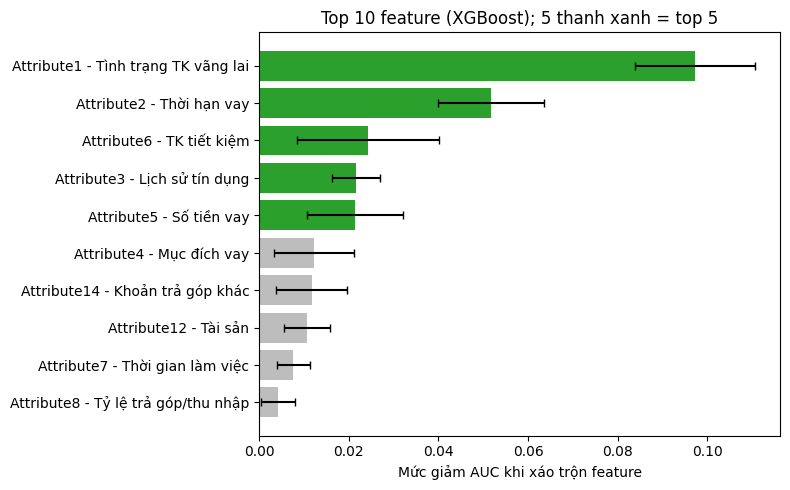

In [ ]:
from sklearn.inspection import permutation_importance

FEATURE_NAMES = {
    "Attribute1": "Tình trạng TK vãng lai", "Attribute2": "Thời hạn vay",
    "Attribute3": "Lịch sử tín dụng",      "Attribute4": "Mục đích vay",
    "Attribute5": "Số tiền vay",           "Attribute6": "TK tiết kiệm",
    "Attribute7": "Thời gian làm việc",    "Attribute8": "Tỷ lệ trả góp/thu nhập",
    "Attribute9": "Tình trạng cá nhân/giới tính", "Attribute10": "Người đồng vay/bảo lãnh",
    "Attribute11": "Thời gian cư trú",     "Attribute12": "Tài sản",
    "Attribute13": "Tuổi",                 "Attribute14": "Khoản trả góp khác",
    "Attribute15": "Nhà ở",                "Attribute16": "Số khoản vay hiện có",
    "Attribute17": "Nghề nghiệp",          "Attribute18": "Số người phụ thuộc",
    "Attribute19": "Điện thoại",           "Attribute20": "Lao động nước ngoài",
}
MODEL_NAME = order[0]
N_REPEATS = 10   # số lần xáo trộn mỗi cột, dùng chung cho 10A và 10B

def cv_perm_importance(est, n_repeats=N_REPEATS):
    """Trả về ma trận (số fold x số feature) giảm AUC khi xáo trộn từng cột gốc."""
    out = []
    for tr, va in skf.split(X_train, y_train):
        m = clone(est).fit(X_train.iloc[tr], y_train.iloc[tr])   # fit chỉ trên train fold
        r = permutation_importance(m, X_train.iloc[va], y_train.iloc[va],
                                   scoring="roc_auc", n_repeats=n_repeats,
                                   random_state=SEED, n_jobs=-1)
        out.append(r.importances_mean)
    return np.array(out)

# Tính cho vài model để xem feature nào được đồng thuận (list để thứ tự cố định)
imp_by_model = {}
for name in dict.fromkeys([MODEL_NAME, "XGBoost", "Random Forest", "Logistic Regression"]):
    imp_by_model[name] = cv_perm_importance(best_estimators[name])
    print(f"[xong] {name}")

def importance_table(mat):
    df = pd.DataFrame({
        "Feature": X_train.columns,
        "Mô tả": [FEATURE_NAMES[c] for c in X_train.columns],
        "Giảm AUC (TB)": mat.mean(axis=0),
        "Std giữa fold": mat.std(axis=0),
    }).sort_values("Giảm AUC (TB)", ascending=False).reset_index(drop=True)
    df.index = df.index + 1
    df.index.name = "Hạng"
    return df

imp = importance_table(imp_by_model[MODEL_NAME])
top5 = imp.head(5)
print(f"\nBảng 10a: Top 5 feature quan trọng nhất ({MODEL_NAME}, permutation importance trên validation fold)")
display(top5.style.format({"Giảm AUC (TB)": "{:.4f}", "Std giữa fold": "{:.4f}"})
        .background_gradient(subset=["Giảm AUC (TB)"], cmap="Greens", vmin=0))

# Đồng thuận giữa các model
cons = pd.DataFrame({
    name: importance_table(mat).set_index("Feature")["Giảm AUC (TB)"].rank(ascending=False).astype(int)
    for name, mat in imp_by_model.items()
})
cons["Số model có trong top 5"] = (cons <= 5).sum(axis=1)
cons.insert(0, "Mô tả", [FEATURE_NAMES[c] for c in cons.index])
print("Bảng 10b: Hạng của từng feature ở từng model (1 = quan trọng nhất)")
display(cons.sort_values("Số model có trong top 5", ascending=False).head(8))

# Biểu đồ
top10 = imp.head(10).iloc[::-1]
colors = ["#2ca02c" if i >= 5 else "#bdbdbd" for i in range(10)]   # 5 thanh cuối (cao nhất) màu xanh
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top10["Feature"] + " - " + top10["Mô tả"], top10["Giảm AUC (TB)"],
        xerr=top10["Std giữa fold"], color=colors, capsize=3)
ax.set_xlabel("Mức giảm AUC khi xáo trộn feature")
ax.set_title(f"Top 10 feature ({MODEL_NAME}); 5 thanh xanh = top 5")
plt.tight_layout(); plt.show()

**Top 5 feature quan trọng nhất (XGBoost, permutation importance trên validation fold):**  
* Attribute1 vượt trội: xáo trộn nó làm AUC giảm gần 0.10, gần gấp đôi feature hạng 2 và gấp 4-5 lần các feature hạng 3-5. Đây là tín hiệu mạnh nhất, khớp với nhận xét EDA ban đầu (tài khoản vãng lai, thời hạn vay, lịch sử tín dụng, tiết kiệm, số tiền vay là các tín hiệu mạnh).
* Attribute2 đứng thứ hai rõ ràng (0.052), phân tách khỏi nhóm sau.
* Hạng 3, 4, 5 sát nhau (0.0242, 0.0216, 0.0214). Std giữa fold của Attribute6 (0.0159) và Attribute5 (0.0108) lớn so với giá trị, nên thứ tự giữa ba feature này không đáng tin. Chỉ nên nói “nhóm 3 feature ngang nhau”.
* Từ hạng 6 trở đi (Mục đích vay, Khoản trả góp khác, Tài sản, Thời gian làm việc, Tỷ lệ trả góp/thu nhập) mức giảm AUC chỉ khoảng 0.004-0.012 và thanh lỗi rộng so với giá trị (Tỷ lệ trả góp/thu nhập gần như chạm 0), tức đóng góp yếu.

**Đồng thuận giữa các model (bảng 10b):**  
* 4 feature có mặt trong top 5 của cả 3 model: Attribute1, Attribute2, Attribute3, Attribute6. Đây là nhóm đáng tin nhất. Attribute1 và Attribute2 đều hạng 1 và 2 ở cả ba model.
* Attribute5 (số tiền vay) nằm top 5 ở XGBoost và Random Forest (hạng 5) nhưng chỉ hạng 13 ở Logistic Regression.
Lý do: số tiền vay tương quan với thời hạn vay (r = 0.62) nên mô hình tuyến tính để Attribute2 “gánh” phần lớn thông tin, còn mô hình cây khai thác được quan hệ phi tuyến của số tiền.
* Attribute8 (tỷ lệ trả góp/thu nhập) chỉ có Logistic Regression xếp hạng 5, còn hai mô hình cây xếp 10 và 12. Đây là feature phụ thuộc loại mô hình, không nên xem là top.
* Attribute10 và Attribute11 ở hạng 14-19 ở mọi model, nhất quán là yếu, khớp với EDA (thời gian cư trú, người đồng vay đóng góp rất ít).

### 10B. Thử bỏ bớt feature (giữ top-k) và xem Accuracy, AUC, cost thay đổi

Với mỗi fold ngoài (cùng `skf` với 10A):
1. Chia train fold thành inner-train (75%) và inner-validation (25%).
2. Fit model trên inner-train, xếp hạng feature bằng permutation importance (ROC-AUC) trên inner-validation, giống 10A.
3. Fit lại model chỉ với top-k feature trên toàn bộ train fold.
4. Đánh giá trên validation fold ngoài, phần chưa từng dùng để xếp hạng.

[xong] fold 1/5
[xong] fold 2/5
[xong] fold 3/5
[xong] fold 4/5
[xong] fold 5/5

Bảng 10c: Giữ top-k feature (XGBoost, OOF trên train). k=20 là đầy đủ feature


,AUC,Gini,Accuracy @0.5,Accuracy @1/6,Cost/khách @1/6,Ngưỡng tối ưu,Cost/khách @tối ưu
Số feature giữ,,,,,,,
20,0.796,0.592,0.757,0.616,0.539,0.15,0.506
15,0.784,0.569,0.760,0.608,0.552,0.22,0.539
10,0.780,0.559,0.751,0.606,0.564,0.21,0.555
7,0.777,0.555,0.760,0.600,0.565,0.20,0.531
5,0.756,0.511,0.750,0.590,0.590,0.16,0.576
3,0.725,0.451,0.706,0.595,0.575,0.18,0.562


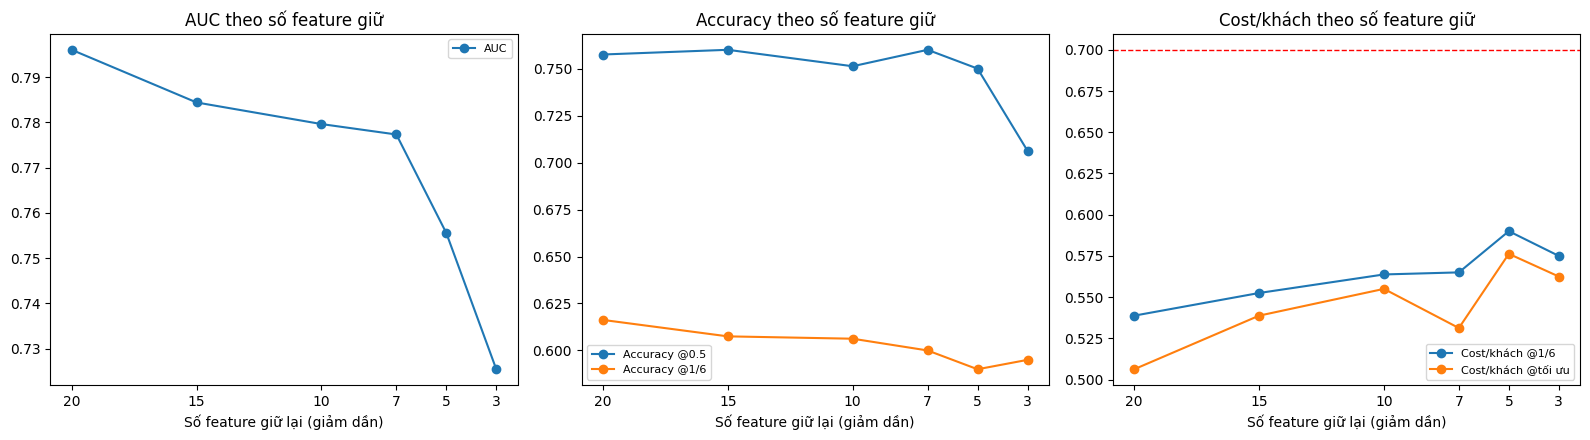

In [ ]:
from sklearn.metrics import accuracy_score

def make_prep(cols):
    """Preprocessor giống Bước 1 nhưng chỉ cho tập cột đang giữ."""
    logs  = [c for c in log_cols if c in cols]
    nums  = [c for c in plain_num_cols if c in cols]
    cats  = [c for c in cat_cols if c in cols]
    tr = []
    if logs: tr.append(("log_num", make_log_pipe(), logs))
    if nums: tr.append(("num", StandardScaler(), nums))
    if cats: tr.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                             min_frequency=30, drop="if_binary",
                                             sparse_output=False), cats))
    return ColumnTransformer(tr, remainder="drop", verbose_feature_names_out=False)

KS_LIST = [20, 15, 10, 7, 5, 3]
base_clf = best_estimators[MODEL_NAME].named_steps["model"]
all_cols = list(X_train.columns)
oof_k = {k: np.zeros(len(X_train)) for k in KS_LIST}

for fold, (tr, va) in enumerate(skf.split(X_train, y_train), 1):
    Xtr, ytr, Xva = X_train.iloc[tr], y_train.iloc[tr], X_train.iloc[va]

    # Xếp hạng feature CHỈ bằng train fold, nhất quán với 10A: importance đo trên dữ liệu
    # model chưa thấy (inner validation), không dùng validation fold ngoài.
    Xin, Xiv, yin, yiv = train_test_split(Xtr, ytr, test_size=0.25, stratify=ytr, random_state=SEED)
    ranker = Pipeline([("prep", make_prep(all_cols)), ("model", clone(base_clf))]).fit(Xin, yin)
    r = permutation_importance(ranker, Xiv, yiv, scoring="roc_auc",
                               n_repeats=N_REPEATS, random_state=SEED, n_jobs=-1)
    ranked = [all_cols[i] for i in np.argsort(-r.importances_mean)]

    for k in KS_LIST:
        cols = ranked[:k]
        pipe = Pipeline([("prep", make_prep(cols)), ("model", clone(base_clf))])
        pipe.fit(Xtr[cols], ytr)
        oof_k[k][va] = pipe.predict_proba(Xva[cols])[:, 1]
    print(f"[xong] fold {fold}/{N_SPLITS}")

# Bảng kết quả
rows = []
for k in KS_LIST:
    p = oof_k[k]
    t_opt, c_opt = best_threshold(y_train, p)
    rows.append({
        "Số feature giữ": k,
        "AUC": roc_auc_score(y_train, p),
        "Gini": 2 * roc_auc_score(y_train, p) - 1,
        "Accuracy @0.5": accuracy_score(y_train, (p >= 0.5).astype(int)),
        "Accuracy @1/6": accuracy_score(y_train, (p >= THEORETICAL_THRESHOLD).astype(int)),
        "Cost/khách @1/6": cost_at_threshold(y_train, p, THEORETICAL_THRESHOLD) / len(y_train),
        "Ngưỡng tối ưu": t_opt,
        "Cost/khách @tối ưu": c_opt / len(y_train),
    })
ablation = pd.DataFrame(rows).set_index("Số feature giữ")

print(f"\nBảng 10c: Giữ top-k feature ({MODEL_NAME}, OOF trên train). k=20 là đầy đủ feature")
display(ablation.style
        .format({"AUC": "{:.3f}", "Gini": "{:.3f}", "Accuracy @0.5": "{:.3f}",
                 "Accuracy @1/6": "{:.3f}", "Cost/khách @1/6": "{:.3f}",
                 "Ngưỡng tối ưu": "{:.2f}", "Cost/khách @tối ưu": "{:.3f}"})
        .highlight_max(subset=["AUC", "Gini", "Accuracy @0.5", "Accuracy @1/6"], props=HL)
        .highlight_min(subset=["Cost/khách @1/6", "Cost/khách @tối ưu"], props=HL))

# Biểu đồ
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
ks = ablation.index
for ax, cols_, title in [
    (axes[0], ["AUC"], "AUC theo số feature giữ"),
    (axes[1], ["Accuracy @0.5", "Accuracy @1/6"], "Accuracy theo số feature giữ"),
    (axes[2], ["Cost/khách @1/6", "Cost/khách @tối ưu"], "Cost/khách theo số feature giữ"),
]:
    for c in cols_:
        ax.plot(ks, ablation[c], marker="o", label=c)
    ax.invert_xaxis(); ax.set_xticks(ks)
    ax.set_xlabel("Số feature giữ lại (giảm dần)"); ax.set_title(title); ax.legend(fontsize=8)
axes[2].axhline(best_trivial / len(y_train), color="red", ls="--", lw=1)
plt.tight_layout(); plt.show()

**Lưu ý:** thứ hạng feature ở 10B được tính trên inner-validation của từng fold (không dùng validation fold ngoài), nên Bảng 10c không bị lạc quan do chọn feature trên chính dữ liệu đánh giá. Các nhận xét dưới đây đã cập nhật theo lần chạy lại.
* AUC giảm dần khi bỏ feature. So với đủ 20 feature (0.796): k=15 giảm 0.012 (0.784), k=10 giảm 0.016 (0.780), k=7 giảm 0.019 (0.777), rồi rơi rõ ở k=5 (0.756, giảm 0.040) và k=3 (0.725, giảm 0.071). Các mức giảm ở k=15 đến 7 nhỏ hơn nhiễu của CV (Std ≈ 0.05), nhưng đều cùng chiều xấu đi.
* Cost không cải thiện ở bất kỳ k nào. Tại ngưỡng 1/6: 0.539 (k=20) so với 0.552, 0.564, 0.565, 0.590, 0.575 ở k = 15, 10, 7, 5, 3. Tại ngưỡng tối ưu: 0.506 so với 0.539, 0.555, 0.531, 0.576, 0.562. Cost @tối ưu không đơn điệu (k=7 tốt hơn k=10, k=3 tốt hơn k=5), nên chênh lệch giữa các k nhỏ là nhiễu; chỉ xu hướng chung (đủ feature là tốt nhất, k ≤ 5 kém rõ về AUC) là đáng tin. Cost @tối ưu còn hơi lạc quan vì ngưỡng được tìm trên chính OOF.
* Với 10 feature, cost @1/6 cao hơn 0.025 so với đủ 20 feature, và mức tiết kiệm so với mốc 0.70 còn khoảng 19% thay vì 23%.
* Từ k=10 xuống k=5, AUC giảm 0.024: các feature hạng 6-10 (mục đích vay, khoản trả góp khác, tài sản, thời gian làm việc, tỷ lệ trả góp) mỗi cái đóng góp nhỏ nhưng cộng lại vẫn có ích.
* Accuracy @0.5 gần như phẳng (0.750-0.760) từ k=20 đến k=5, chỉ rơi ở k=3 (0.706). Accuracy kém nhạy với việc bỏ feature, nên không phù hợp để đánh giá tác động này; AUC và cost phản ánh rõ hơn.

### Quyết định đề xuất:

* Giữ nguyên model 20 feature đã chốt ở Bước 9. Bỏ feature không cải thiện cost ở bất kỳ k nào, và nếu train lại với tập con thì phải tune lại trong CV và chạm test thêm lần nữa, làm test mất giá trị.
* Mô hình gọn 10 feature chỉ nên xem là phương án đơn giản hóa nếu ưu tiên khả năng giải thích hơn chất lượng, với cái giá khoảng 0.016 AUC và 0.025 cost/khách (@1/6). Không dùng kết quả này để thay model đã chốt.
* Không nên rút xuống 5 hoặc 3 feature: AUC giảm 0.04 đến 0.07 và cost @1/6 tăng khoảng 0.04-0.05 so với đầy đủ, mất bớt lợi ích so với mốc 0.70.

### Kết luận:
Phân tích permutation importance trên validation fold cho thấy năm feature quan trọng nhất của XGBoost là tình trạng tài khoản vãng lai (giảm AUC 0.097), thời hạn vay (0.052), tài khoản tiết kiệm, lịch sử tín dụng và số tiền vay (khoảng 0.021-0.024). Bốn feature đầu đồng thuận ở cả XGBoost, Random Forest và Logistic Regression; số tiền vay chỉ quan trọng với các mô hình cây. Thí nghiệm giữ top-k trong CV cho thấy bỏ bớt feature không cải thiện chất lượng: AUC giảm từ 0.796 (20 feature) xuống 0.784 (15), 0.780 (10), 0.777 (7), rồi 0.756 (5) và 0.725 (3), còn cost không thấp hơn ở bất kỳ k nào. Vì vậy mô hình cuối cùng giữ đầy đủ 20 feature; mô hình 10 feature chỉ là phương án đơn giản hóa đánh đổi một phần chất lượng.